# 01 — Problem, data, and visual findings

- Evidence phase: what the supplied data can say about H/A/D.
- Main question: where each signal stops being reliable.
- Plots: context before and after each event.
- Public five-minute window: the complete analysis scope and comparison interval.
- Unit of analysis: transition-centred event windows inside that five-minute interval.
- For each event: ball path/speed → candidate departure/reception anchors → H/A/D comparison.
- No training or hand-labelled examples.
- Workflow: engineered features → scenario identification → ground-truth cross-reference → reusable transition rule.
- Ground truth: pattern discovery and calibration only; never copied into the final predictor.
- Outputs: anchors, scenarios, confidence scores, and dynamic-programming decoder.

## 0. What we are given

| Source | What it contains | What it does **not** give us directly |
|---|---|---|
| ATD | Per-frame ball and temporary player-slot x/y positions; some movement fields | A trustworthy H/A/D possession label; persistent player identity; usable ball height in this export |
| Smart Tagging | Broad football-phase intervals such as Build Up, Progression, Long Ball, transitions, and Set Pieces | Exact touch, reception, possession-switch, or dead-ball boundary; intervals are too broad for frame-level labels |
| Homography | A per-frame mapping between pitch coordinates and broadcast image pixels | It does not itself identify possession |
| Public five-minute labels | Released H/A/D labels for one short sanity window | Labels for the hidden graded frames |

- ATD x/y: already pitch coordinates; no homography needed for the tactical baseline.
- Homography: useful for broadcast ↔ pitch alignment; not possession inference.
- Homography cannot recover a hidden ball or decide who controls it.
- Missing in the inspected export: usable `ball_z`, `ball_speed`, and `ball_owning_team_id`.
- `_d` fields: not reliable enough for core evidence.

In [1]:
# Purpose: load the raw sources and build the same canonical feature table used later.
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / 'possession').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from games import asset_paths
from possession.baseline_pipeline import ClosestTeamRuleModel
from possession.calculations.features import build_engineered_features
from possession.calculations.plotting import (
    PITCH_LENGTH_M, PITCH_WIDTH_M, plot_trajectory_window, plot_evidence_window, plot_timeline_window,
    select_evidence_window, select_representative_ball_gap, select_ball_gap_event_window,
)
from starter.load_smart_tagging import load as load_smart_tagging

paths = asset_paths()
PUBLIC_START, PUBLIC_END = 11185, 18684
features = build_engineered_features()
features = features.loc[features.frame.between(PUBLIC_START, PUBLIC_END)].copy()
team_by_slot = __import__('possession.baseline_pipeline', fromlist=['slot_team_map']).slot_team_map(paths['atd_meta'])
smart_tags = load_smart_tagging()
public_gt = pd.read_csv(ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv')
gt_by_frame = public_gt.set_index('frame')['label']
print(f'features: {features.shape[0]:,} frames × {features.shape[1]:,} columns')
print('graded rows:', int(features['graded'].sum()), 'of', len(features))
print('slots:', len(team_by_slot), '| smart tags:', len(smart_tags))
display(features[['frame', 'ball_x', 'ball_y', 'closest_team', 'closest_distance_m', 'scenario_context']].head())

features: 7,500 frames × 439 columns
graded rows: 7500 of 7500
slots: 46 | smart tags: 638


,frame,ball_x,ball_y,closest_team,closest_distance_m,scenario_context
11185,11185,NaN,NaN,None,NaN,DEAD
11186,11186,NaN,NaN,None,NaN,DEAD
11187,11187,0.50431,0.48090,A,0.424743,DEAD
11188,11188,0.51057,0.48349,A,1.124072,RESTART_LIVE_BOUNDARY
11189,11189,0.51691,0.48613,A,1.840058,RESTART_LIVE_BOUNDARY


## 1. Public five-minute ball locations

The tactical file supplies the ball x/y location. The public labels are a separate time-indexed release. The first plot therefore shows the observed ball path, while the colour strip below is the released H/A/D label. Missing ball coordinates are not silently treated as a possession switch.

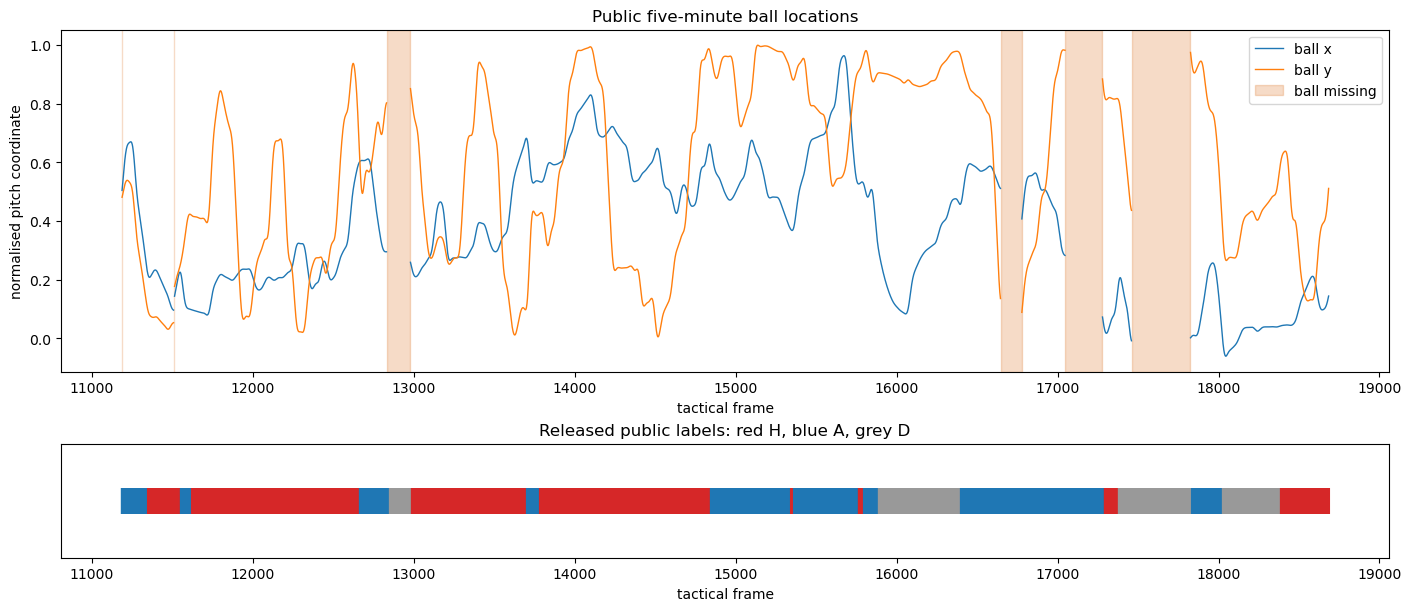

In [2]:
# Purpose: show the public interval's observed ball path and released label strip.
pub = features.loc[features.frame.between(PUBLIC_START, PUBLIC_END)].copy()
fig, (ax_path, ax_lab) = plt.subplots(2, 1, figsize=(14, 6), constrained_layout=True, gridspec_kw={'height_ratios':[3, 1]})
ax_path.plot(pub.frame, pub.ball_x, label='ball x', lw=1)
ax_path.plot(pub.frame, pub.ball_y, label='ball y', lw=1)
missing = pub.ball_x.isna() | pub.ball_y.isna()
starts = np.flatnonzero(missing.to_numpy() & ~np.r_[False, missing.to_numpy()[:-1]])
ends = np.flatnonzero(missing.to_numpy() & ~np.r_[missing.to_numpy()[1:], False])
for left, right in zip(starts, ends):
    ax_path.axvspan(pub.frame.iloc[left], pub.frame.iloc[right], color='#d95f02', alpha=.22, label='ball missing' if left == starts[0] else None)
ax_path.set(title='Public five-minute ball locations', xlabel='tactical frame', ylabel='normalised pitch coordinate')
ax_path.legend()
try:
    gt = gt_by_frame.reindex(range(PUBLIC_START, PUBLIC_END + 1)).to_numpy()
    colours = {'H':'#d62728', 'A':'#1f77b4', 'D':'#999999'}
    ax_lab.scatter(np.arange(PUBLIC_START, PUBLIC_END + 1), np.zeros(len(gt)), c=[colours.get(str(v), '#ffffff') for v in gt], marker='|', s=350)
    ax_lab.set_title('Released public labels: red H, blue A, grey D')
except Exception as exc:
    ax_lab.text(0.01, 0.5, f'Public label loader unavailable: {exc}', transform=ax_lab.transAxes)
ax_lab.set_yticks([]); ax_lab.set_xlabel('tactical frame')
plt.show()

## 2. Smart Tagging: useful context, not a frame label

- One bar: one tag interval.
- Colours: red Barcelona, blue Athletic, grey N/A.
- Defending codes: tagged team is the defending side; attacking mirror for the other team.
- Set Pieces: provider intervals; start is the useful boundary, not the whole interval.

**Useful clues**
- Set-piece start → likely dead-ball boundary.
- Goal → restart regime.
- Team metadata → weak phase context.
- Long Ball → nearest-player possession unsafe.
- Transition tag → inspect reception and switch evidence.

**Why not direct labels**
- Broad intervals.
- Overlapping tags.
- Phase description, not controlling player.
- Boundary may precede or follow the actual touch.
- Long set-piece interval would erase live play if all frames became D.
- Operational use: select checks and scenarios; never automatic H/A switches.

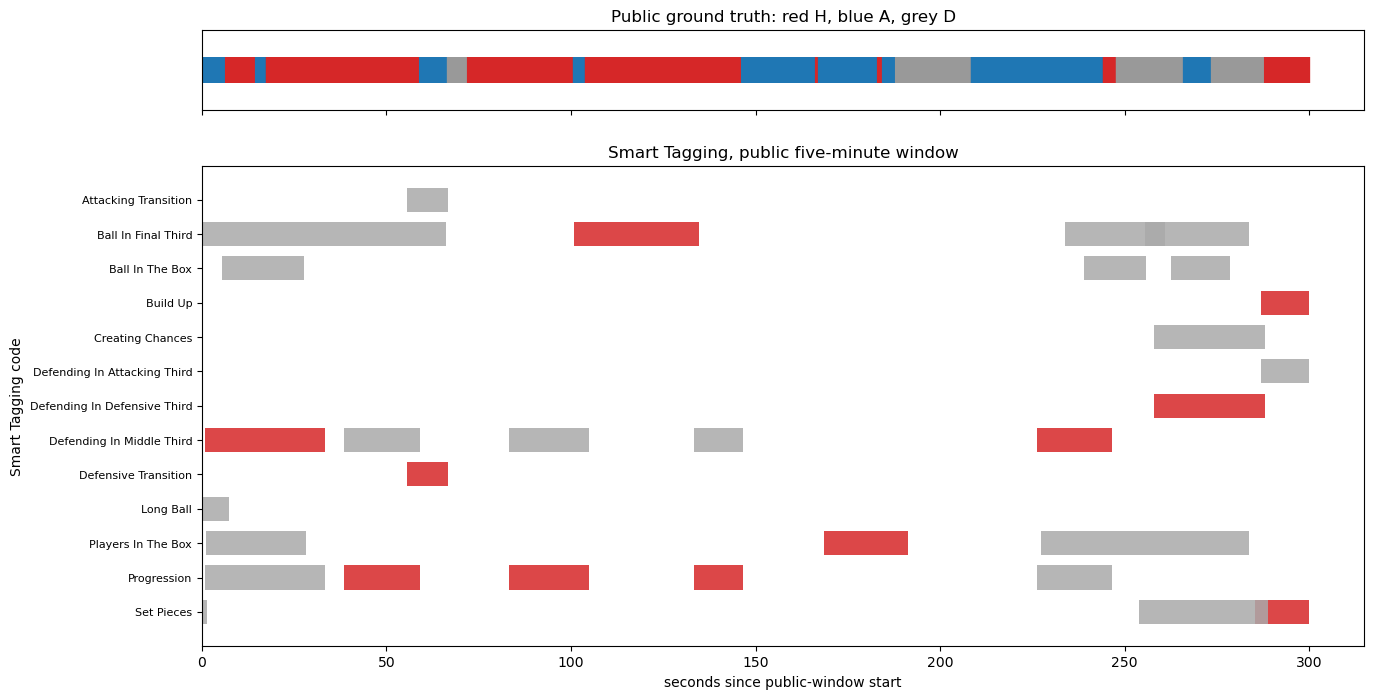

,code,team,intervals
3,BALL IN THE BOX,Atletic Club,3
15,PROGRESSION,Barcelona,3
8,DEFENDING IN MIDDLE THIRD,Atletic Club,3
1,BALL IN FINAL THIRD,Atletic Club,3
9,DEFENDING IN MIDDLE THIRD,Barcelona,2
14,PROGRESSION,Atletic Club,2
12,PLAYERS IN THE BOX,Atletic Club,2
11,LONG BALL,Atletic Club,1
17,SET PIECES,Barcelona,1
16,SET PIECES,Atletic Club,1


In [3]:
# Purpose: reproduce the Smart Tagging timeline and place public truth underneath it.
tag_rows = []
for tag in smart_tags:
    code = str(tag.get('code', tag.get('Code', 'unknown')))
    start = tag.get('start_frame', tag.get('start'))
    end = tag.get('end_frame', tag.get('end', start))
    meta = tag.get('tags', {}) or {}
    team = meta.get('Team', tag.get('team_side', tag.get('team')))
    tag_rows.append({'code': code, 'start_frame': start, 'end_frame': end, 'team': team})
tags = pd.DataFrame(tag_rows)
tags = tags[pd.to_numeric(tags.start_frame, errors='coerce').notna()].copy()
tags[['start_frame','end_frame']] = tags[['start_frame','end_frame']].apply(pd.to_numeric, errors='coerce')
tags = tags.loc[(tags.end_frame > PUBLIC_START) & (tags.start_frame < PUBLIC_END)]
codes = sorted(tags.code.unique())
fig, (ax_gt, ax_tags) = plt.subplots(2, 1, figsize=(15, 8), sharex=True, gridspec_kw={'height_ratios':[1, 6]})
team_colour = {'H':'#d62728', 'A':'#1f77b4', 'Barcelona':'#d62728', 'Athletic':'#1f77b4'}
for _, row in tags.iterrows():
    y = codes.index(row.code)
    a, b = max(row.start_frame, PUBLIC_START), min(row.end_frame, PUBLIC_END)
    ax_tags.barh(y, (b-a)/25, left=(a-PUBLIC_START)/25, height=.7, color=team_colour.get(row.team, '#aaaaaa'), alpha=.85)
ax_tags.set_yticks(range(len(codes))); ax_tags.set_yticklabels([c.title() for c in codes], fontsize=8); ax_tags.invert_yaxis()
ax_tags.set_ylabel('Smart Tagging code'); ax_tags.set_xlabel('seconds since public-window start')
try:
    gt = gt_by_frame.reindex(range(PUBLIC_START, PUBLIC_END + 1)).to_numpy()
    ax_gt.scatter(np.arange(len(gt))/25, np.zeros(len(gt)), c=[{'H':'#d62728','A':'#1f77b4','D':'#999999'}.get(str(v),'#ffffff') for v in gt], marker='|', s=350)
    ax_gt.set_title('Public ground truth: red H, blue A, grey D')
except Exception as exc: ax_gt.set_title(f'Ground truth unavailable: {exc}')
ax_gt.set_yticks([]); ax_tags.set_title('Smart Tagging, public five-minute window'); plt.show()
display(tags.groupby(['code','team']).size().rename('intervals').reset_index().sort_values('intervals', ascending=False).head(20))

## 3. A comfortable-possession frame

The requested frame is `11,185 + 25 × 30 = 11,935`. 

This is a geometry example, not a label copied from ground truth. If one player is close to the ball, the same team's second-closest player is not close, and the opponent team is far away, nearest-player geometry is a strong H/A anchor. This suggests the team on the ball (team of the player closest to the ball) is comfortable in possession. 

Our approach is to label as many of these frames as possible with H/A first.

The plot uses the real pitch orientation: x is 0–105.3 m and y is 0–68 m, with the origin at the pitch corner.

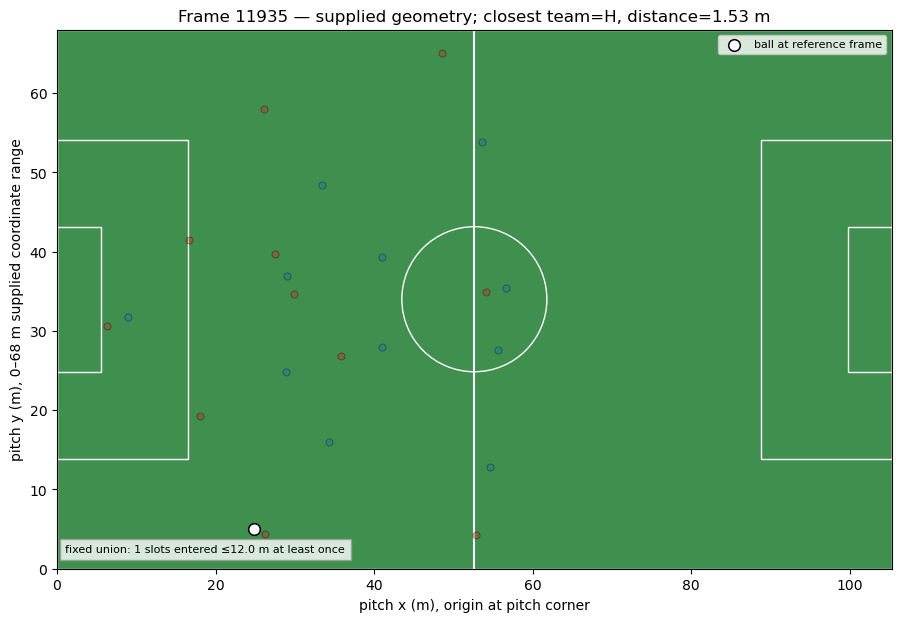

,frame,ball_x,ball_y,closest_team,closest_slot,closest_distance_m,team_distance_margin_m,h_players_within_radius,a_players_within_radius
11935,11935,0.23546,0.07303,H,15.0,1.5317,12.992012,1,0


In [4]:
# Purpose: inspect the requested frame as a pitch snapshot.
frame_i = 11185 + 25 * 30
row = features.iloc[(features.frame - frame_i).abs().argmin()]
fig, ax = plt.subplots(figsize=(11, 7))
plot_trajectory_window(features, int(row.frame), int(row.frame), team_by_slot=team_by_slot, reference_frame=int(row.frame), ax=ax)
ax.set_title(f'Frame {int(row.frame)} — supplied geometry; closest team={row.closest_team}, distance={row.closest_distance_m:.2f} m')
plt.show()
display(features.loc[features.frame.eq(row.frame), ['frame','ball_x','ball_y','closest_team','closest_slot','closest_distance_m','team_distance_margin_m','h_players_within_radius','a_players_within_radius']])

## 4. Dead-ball evidence

- Ball outside pitch rectangle → physical dead-ball evidence.
- Boundary alone cannot distinguish corner, throw-in, goal kick, or tracking error.
- Smart Tagging Set Pieces → second clue; interval too wide for exact boundary.
- Hierarchy: explicit restart/goal event → out-of-bounds evidence → tag evidence.
- Keep D until controlled live-ball possession.
- Do not switch H/A on the first moving ball.

In [5]:
# Purpose: quantify physical out-of-bounds evidence and compare it with public D.
p = features.loc[features.frame.between(PUBLIC_START, PUBLIC_END)].copy()
p['ball_out_of_bounds'] = p.ball_x.notna() & p.ball_y.notna() & ((p.ball_x < 0) | (p.ball_x > 1) | (p.ball_y < 0) | (p.ball_y > 1))
set_piece = p.get('smart_set_piece', pd.Series(False, index=p.index)).fillna(False)
print('public rows:', len(p))
print('out-of-bounds rows:', int(p.ball_out_of_bounds.sum()))
print('Smart Tagging set-piece rows:', int(set_piece.sum()))
try:
    p['public_label'] = gt_by_frame.reindex(p.frame).to_numpy()
    print(pd.crosstab(p.public_label, p.ball_out_of_bounds, normalize='index').round(3))
except Exception as exc: print('public comparison unavailable:', exc)
pd.DataFrame({'signal':['ball_out_of_bounds','smart_set_piece'], 'rows':[int(p.ball_out_of_bounds.sum()), int(set_piece.sum())]})

public rows: 7500
out-of-bounds rows: 106
Smart Tagging set-piece rows: 1189
ball_out_of_bounds  False  True 
public_label                    
A                   0.999  0.001
D                   0.929  0.071
H                   1.000  0.000


,signal,rows
0,ball_out_of_bounds,106
1,smart_set_piece,1189


## 5. Missing ball: inspect the path before and after

- Internal gap plot: observed path, dotted missing bridge, nearby players, nearest-player geometry.
- Speed plot: observed speed before and after the gap.
- Boundary labels: evidence at the last/next observed frames.
- Ground-truth audit: mark every observed label boundary across the same window.
- H↔A boundary: candidate possession transition; D↔H/A: dead-ball release/restart boundary.
- Header/foot identity: not required for the possession rule; treat the missing interval as a physical uncertainty.
- Missing interval: unresolved until geometry and scenario rules agree.
- Interpolation: diagnostic only; not proof of uninterrupted possession.

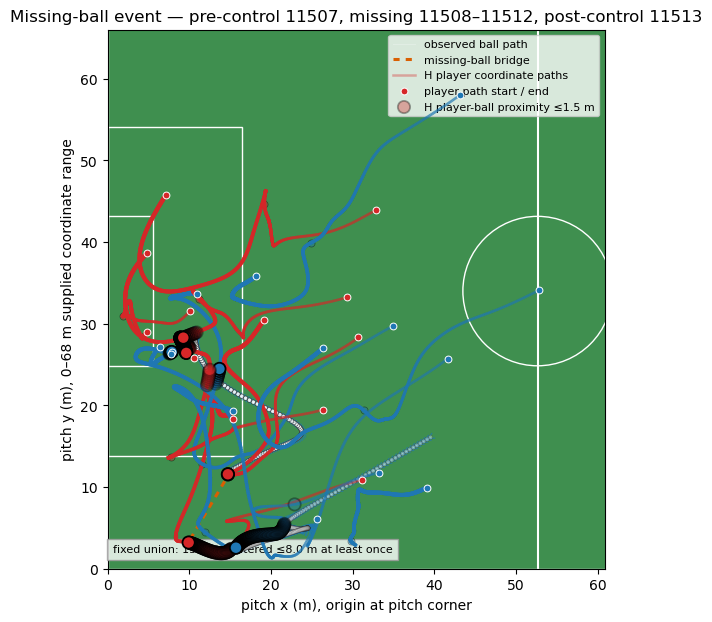

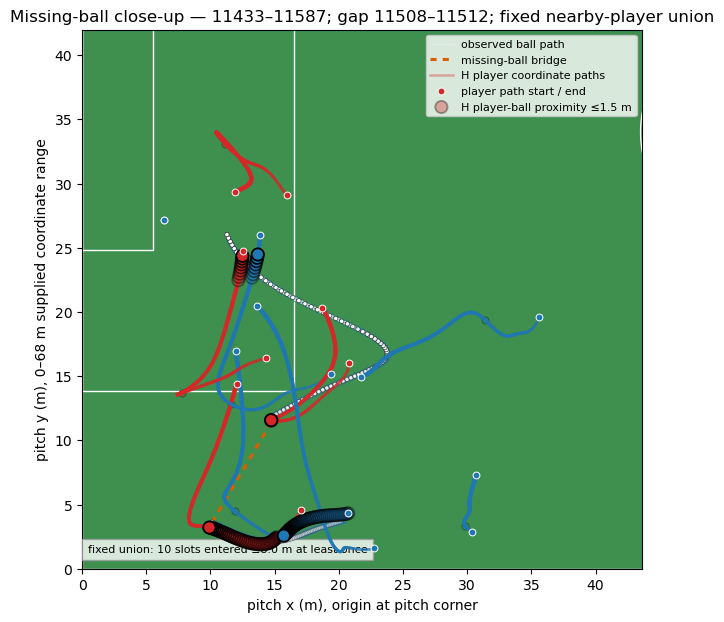

""


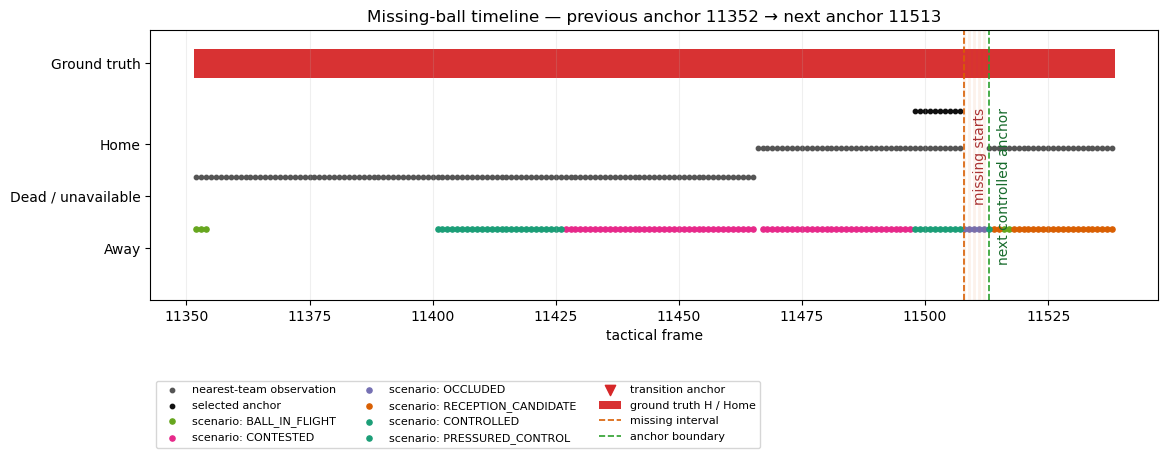

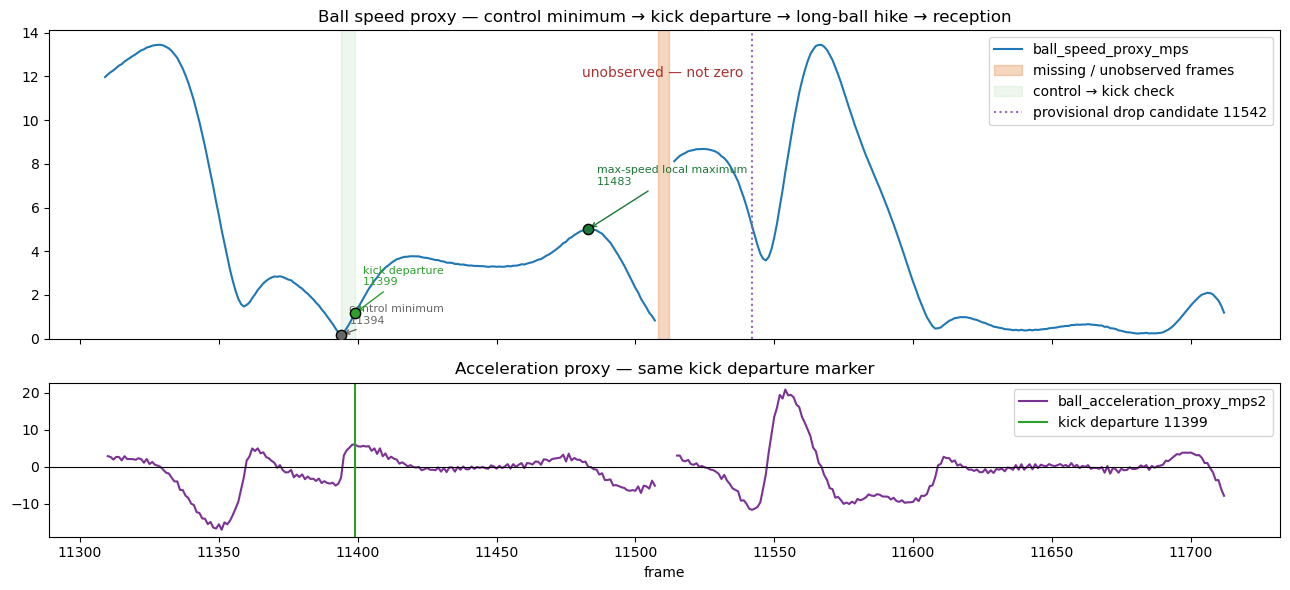

computed departure candidates: previous_anchor=11352; slots=[3, 35, 45]; control_frame=11394; kick_frame=11399; max_speed_frame=11483; observed_path_distance_m=70.48; speed_hike_mps=4.84; provisional_drop_frame=11542


,frame,ball_x,ball_y,closest_team,scenario_context
11308,11308,0.37541,0.23653,A,BALL_IN_FLIGHT
11507,11507,0.09613,0.05331,H,CONTROLLED
11513,11513,0.14364,0.17714,H,CONTROLLED
11712,11712,0.07993,0.39482,A,CONTESTED


In [6]:
# Purpose: choose a data-driven internal gap and show context on both sides.
gap = select_representative_ball_gap(features)
if gap is None:
    print('No internal ball gap found.')
else:
    gap_start, gap_end = gap
    # Search farther back from the gap: previous controlled anchor → kick → flight → reception.
    # Display context only; not a fixed possession rule or label look-ahead threshold.
    event_window = select_ball_gap_event_window(features, gap, minimum_context_frames=200, control_radius_m=2.5)
    start, end = event_window['start_frame'], event_window['end_frame']
    fig, ax = plt.subplots(figsize=(12, 7))
    local = features.loc[features.frame.between(start, end)].copy()
    # Search across the gap for the largest observed low → high speed change.
    # This is the long-ball proxy: departure evidence before the gap and
    # flight/reception evidence after it.
    local['ball_speed_proxy_mps'] = np.hypot(local.ball_x.diff()*PITCH_LENGTH_M, local.ball_y.diff()*PITCH_WIDTH_M) * 25
    local['ball_acceleration_proxy_mps2'] = local['ball_speed_proxy_mps'].diff() * 25
    local['ball_step_distance_m'] = np.hypot(local.ball_x.diff()*PITCH_LENGTH_M, local.ball_y.diff()*PITCH_WIDTH_M)
    observed_path_distance_m = float(local['ball_step_distance_m'].sum())
    pre_gap = local.loc[local.frame.lt(gap_start) & local.ball_speed_proxy_mps.notna()]
    post_gap = local.loc[local.frame.gt(gap_end) & local.ball_speed_proxy_mps.notna()]
    speed_table = local.loc[local.ball_speed_proxy_mps.notna(), ['frame', 'ball_speed_proxy_mps']]
    low_speed_frame = kicker_frame = hike_end_frame = None
    if len(pre_gap) >= 2:
        # Prefer a launch signature entirely before the missing interval.
        pair_table = pre_gap[['frame', 'ball_speed_proxy_mps']].merge(pre_gap[['frame', 'ball_speed_proxy_mps']], how='cross', suffixes=('_before', '_after'))
        pair_table = pair_table.loc[pair_table.frame_after > pair_table.frame_before].copy()
        pair_table['speed_hike_mps'] = pair_table.ball_speed_proxy_mps_after - pair_table.ball_speed_proxy_mps_before
        best_pair = pair_table.loc[pair_table.speed_hike_mps.idxmax()]
        low_speed_frame = int(best_pair.frame_before)
        hike_end_frame = int(best_pair.frame_after)
        rise = local.loc[local.frame.between(low_speed_frame, hike_end_frame)].dropna(subset=['ball_acceleration_proxy_mps2'])
        kicker_frame = int(rise.loc[rise['ball_acceleration_proxy_mps2'].idxmax(), 'frame'])
    elif len(pre_gap) and len(post_gap):
        # Fallback when the pre-gap ball trace is too short.
        pair_table = pre_gap[['frame', 'ball_speed_proxy_mps']].merge(post_gap[['frame', 'ball_speed_proxy_mps']], how='cross', suffixes=('_before', '_after'))
        pair_table['speed_hike_mps'] = pair_table.ball_speed_proxy_mps_after - pair_table.ball_speed_proxy_mps_before
        best_pair = pair_table.loc[pair_table.speed_hike_mps.idxmax()]
        low_speed_frame = int(best_pair.frame_before)
        hike_end_frame = int(best_pair.frame_after)
        rise = local.loc[local.frame.between(low_speed_frame, hike_end_frame)].dropna(subset=['ball_acceleration_proxy_mps2'])
        kicker_frame = int(rise.loc[rise['ball_acceleration_proxy_mps2'].idxmax(), 'frame'])
    elif len(speed_table) >= 2:
        pair_table = speed_table.merge(speed_table, how='cross', suffixes=('_before', '_after'))
        pair_table = pair_table.loc[pair_table.frame_after > pair_table.frame_before].copy()
        pair_table['speed_hike_mps'] = pair_table.ball_speed_proxy_mps_after - pair_table.ball_speed_proxy_mps_before
        best_pair = pair_table.loc[pair_table.speed_hike_mps.idxmax()]
        low_speed_frame = int(best_pair.frame_before)
        hike_end_frame = int(best_pair.frame_after)
        rise = local.loc[local.frame.between(low_speed_frame, hike_end_frame)].dropna(subset=['ball_acceleration_proxy_mps2'])
        kicker_frame = int(rise.loc[rise['ball_acceleration_proxy_mps2'].idxmax(), 'frame'])
    # Separate control from kick departure: control is the local speed minimum;
    # departure is the strongest positive acceleration after that minimum.
    control_frame = None
    if kicker_frame is not None:
        speed_valid = local.loc[local.frame.le(kicker_frame) & local.ball_speed_proxy_mps.notna()].copy()
        speed_valid['local_min'] = speed_valid.ball_speed_proxy_mps.eq(speed_valid.ball_speed_proxy_mps.rolling(9, center=True, min_periods=1).min())
        minima = speed_valid.loc[speed_valid.local_min & speed_valid.frame.between(kicker_frame - 40, kicker_frame)]
        if not minima.empty:
            control_frame = int(minima.iloc[-1].frame)
    if control_frame is None:
        control_frame = low_speed_frame
    # The high point is a local speed maximum, not merely the end of a pairwise hike.
    max_speed_frame = hike_end_frame
    if kicker_frame is not None:
        max_candidates = local.loc[local.frame.between(kicker_frame, gap_start - 1) & local.ball_speed_proxy_mps.notna()].copy()
        if not max_candidates.empty:
            max_candidates['local_max'] = max_candidates.ball_speed_proxy_mps.eq(max_candidates.ball_speed_proxy_mps.rolling(9, center=True, min_periods=1).max())
            local_maxima = max_candidates.loc[max_candidates.local_max]
            if not local_maxima.empty:
                max_speed_frame = int(local_maxima.loc[local_maxima.ball_speed_proxy_mps.idxmax(), 'frame'])
    deceleration_frame = None if post_gap.empty else int(post_gap.loc[post_gap['ball_acceleration_proxy_mps2'].idxmin(), 'frame'])
    prior_controls = features.loc[(features.frame.le(control_frame if control_frame is not None else gap_start - 1)) & (features.closest_distance_m.le(2.5))]
    previous_anchor_frame = None if prior_controls.empty else int(prior_controls.iloc[-1].frame)
    departure = features.loc[features['frame'].isin([previous_anchor_frame, control_frame, kicker_frame, gap_start-1])]
    departure_slots = sorted({int(v) for v in departure['closest_slot'].dropna().tolist()})
    plot_trajectory_window(features, start, end, team_by_slot=team_by_slot, reference_frame=(gap_start+gap_end)//2, nearby_radius_m=8.0, nearby_count=None, include_slots=departure_slots, zoom_to_involved=True, show_all_reference_players=False, ax=ax)
    ax.set_title(f"Missing-ball event — pre-control {event_window['pre_control_frame']}, missing {gap_start}–{gap_end}, post-control {event_window['post_control_frame']}")
    plt.show()
    # Separate close-up: bounded backtrack/forward context around the gap.
    zoom_start = max(0, gap_start - 75)
    zoom_end = min(int(features.frame.max()), gap_end + 75)
    fig_zoom, zoom_ax = plt.subplots(figsize=(10, 7))
    plot_trajectory_window(features, zoom_start, zoom_end, team_by_slot=team_by_slot, reference_frame=(gap_start + gap_end)//2, nearby_radius_m=8.0, nearby_count=None, include_slots=departure_slots, zoom_to_involved=True, show_all_reference_players=False, ax=zoom_ax)
    zoom_ax.set_title(f"Missing-ball close-up — {zoom_start}–{zoom_end}; gap {gap_start}–{gap_end}; fixed nearby-player union")
    plt.show()
    # Timeline: continue forward until the next computed controlled-ball anchor.
    timeline_start = previous_anchor_frame if previous_anchor_frame is not None else start
    timeline_end = min(int(features.frame.max()), event_window['post_control_frame'] + 25)
    fig_timeline, timeline_ax = plt.subplots(figsize=(13, 3.5))
    plot_timeline_window(features, timeline_start, timeline_end, ground_truth=gt_by_frame, ax=timeline_ax)
    # Public labels are used here only to audit where the transition actually occurs.
    gt_long = gt_by_frame.reindex(range(timeline_start, timeline_end + 1))
    gt_changes = gt_long.loc[gt_long.ne(gt_long.shift()) & gt_long.notna() & gt_long.shift().notna()]
    gt_transition_rows = []
    for frame, after_label in gt_changes.items():
        before_label = gt_long.loc[frame - 1]
        gt_transition_rows.append({'transition_frame': int(frame), 'from': before_label, 'to': after_label, 'frames_from_missing_start': int(frame - gap_start)})
    gt_transition_table = pd.DataFrame(gt_transition_rows)
    display(gt_transition_table)
    for row in gt_transition_rows:
        is_possession_switch = {row['from'], row['to']} == {'H', 'A'}
        timeline_ax.axvline(row['transition_frame'], color='#111111' if is_possession_switch else '#777777', linestyle=':', linewidth=1.5, alpha=.9)
        timeline_ax.annotate(f"GT {row['from']}→{row['to']}\n{row['transition_frame']}", xy=(row['transition_frame'], 1.75), xytext=(4, 0), textcoords='offset points', rotation=90, va='top', fontsize=8, color='#111111' if is_possession_switch else '#777777')
    timeline_ax.set_title(f'Missing-ball timeline — previous anchor {timeline_start} → next anchor {event_window["post_control_frame"]}')
    timeline_ax.axvline(gap_start, color='#d95f02', linestyle='--', linewidth=1.2, label='missing interval')
    timeline_ax.annotate('missing starts', xy=(gap_start, 1.35), xytext=(6, 0), textcoords='offset points', color='#a33', rotation=90, va='top')
    timeline_ax.axvline(event_window['post_control_frame'], color='#2ca02c', linestyle='--', linewidth=1.2, label='anchor boundary')
    timeline_ax.annotate('next controlled anchor', xy=(event_window['post_control_frame'], 1.35), xytext=(6, 0), textcoords='offset points', color='#176b2c', rotation=90, va='top')
    timeline_ax.legend(loc='upper left', bbox_to_anchor=(0, -0.28), ncol=3, fontsize=8)
    plt.show()
    fig_speed, (speed_ax, accel_ax) = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
    local.plot(x='frame', y='ball_speed_proxy_mps', ax=speed_ax, title='Ball speed proxy — control minimum → kick departure → long-ball hike → reception', legend=False)
    local.plot(x='frame', y='ball_acceleration_proxy_mps2', ax=accel_ax, title='Acceleration proxy — same kick departure marker', legend=False, color='#7b3294')
    accel_ax.axhline(0, color='black', linewidth=.8)
    speed_ax.set_ylim(bottom=0)
    if gap_start == gap_end:
        speed_ax.axvline(gap_start, color='#d95f02', alpha=.8, linewidth=2, label='missing / unobserved frame')
        pass
    else:
        speed_ax.axvspan(gap_start, gap_end, color='#d95f02', alpha=.25, label='missing / unobserved frames')
        pass
    def _mark_speed(frame, label, color, y_offset=0):
        if frame is None:
            return
        point = local.loc[local.frame.eq(frame), ['frame', 'ball_speed_proxy_mps']].dropna()
        if point.empty:
            return
        x0, y0 = float(point.frame.iloc[0]), float(point.ball_speed_proxy_mps.iloc[0])
        speed_ax.scatter([x0], [y0], s=55, color=color, edgecolor='black', zorder=5)
        speed_ax.annotate(f'{label}\n{int(x0)}', xy=(x0, y0), xytext=(6, 8 + y_offset), textcoords='offset points', color=color, fontsize=8, arrowprops={'arrowstyle':'->', 'color':color})
    if low_speed_frame is not None:
        _mark_speed(control_frame, 'control minimum', '#666666')
    if kicker_frame is not None:
        _mark_speed(kicker_frame, 'kick departure', '#2ca02c', 12)
    if max_speed_frame is not None:
        _mark_speed(max_speed_frame, 'max-speed local maximum', '#1b7837', 24)
    if control_frame is not None and kicker_frame is not None and control_frame < kicker_frame:
        speed_ax.axvspan(control_frame, kicker_frame, color='#2ca02c', alpha=.08, label='control → kick check')
    if deceleration_frame is not None:
        speed_ax.axvline(deceleration_frame, color='#9467bd', linestyle=':', linewidth=1.5, label=f'provisional drop candidate {deceleration_frame}')
    speed_ax.text((gap_start+gap_end)/2, speed_ax.get_ylim()[1]*0.85, 'unobserved — not zero', ha='center', color='#a33')
    if kicker_frame is not None:
        accel_ax.axvline(kicker_frame, color='#2ca02c', linewidth=1.5, label=f'kick departure {kicker_frame}')
    speed_ax.legend(); accel_ax.legend(); plt.tight_layout(); plt.show()
    hike = np.nan
    if low_speed_frame is not None and max_speed_frame is not None:
        low_speed = local.loc[local.frame.eq(low_speed_frame), 'ball_speed_proxy_mps']
        kick_speed = local.loc[local.frame.eq(max_speed_frame), 'ball_speed_proxy_mps']
        if not low_speed.empty and not kick_speed.empty:
            hike = float(kick_speed.iloc[0] - low_speed.iloc[0])
    print(f'computed departure candidates: previous_anchor={previous_anchor_frame}; slots={departure_slots}; control_frame={control_frame}; kick_frame={kicker_frame}; max_speed_frame={max_speed_frame}; observed_path_distance_m={observed_path_distance_m:.2f}; speed_hike_mps={hike:.2f}; provisional_drop_frame={deceleration_frame}')
    display(local.loc[local.frame.isin([start, gap_start-1, gap_end+1, end]), ['frame','ball_x','ball_y','closest_team','scenario_context']])

## 6. Transition evidence: frames before, at, and after H↔A

- Transition plot: frames before, at, and after a candidate boundary.
- Evidence: prior team, ambiguous live-ball scenario, later team/reception.
- Nearest player: trusted only for comfortable control.
- Long ball, through ball, race, contest, occlusion: scenario checks.
- Scenario: trajectory context.
- Learning step: compare feature-defined cases with public H/A/D to identify repeatable transition signatures.
- Deployment step: apply the learned signature to unseen match data without frame-specific labels.
- H/A/D: retained until evidence is strong enough to switch.

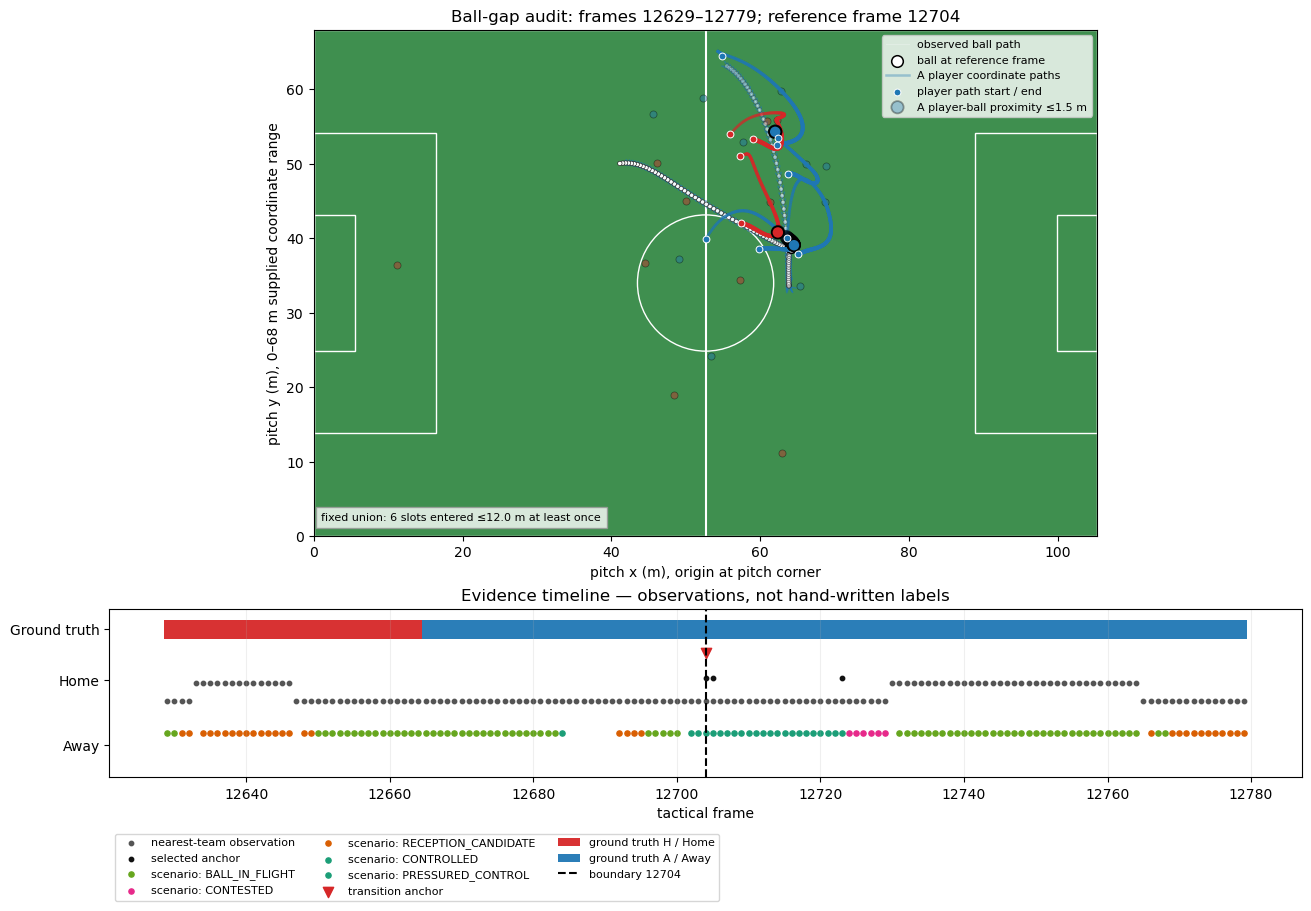

,frame,closest_team,closest_distance_m,team_distance_margin_m,scenario_context,transition_anchor
12699,12699,A,3.205144,-4.953553,BALL_IN_FLIGHT,False
12700,12700,A,2.883942,-4.923027,BALL_IN_FLIGHT,False
12701,12701,A,2.592194,-4.887698,UNKNOWN,False
12702,12702,A,2.331038,-4.848152,PRESSURED_CONTROL,False
12703,12703,A,2.098152,-4.805127,PRESSURED_CONTROL,False
12704,12704,A,1.894235,-4.757749,CONTROLLED,True
12705,12705,A,1.717697,-4.706192,CONTROLLED,False
12706,12706,A,1.565779,-4.650290,CONTROLLED,False
12707,12707,A,1.438463,-4.591393,CONTROLLED,False
12708,12708,A,1.330930,-4.527872,CONTROLLED,False


In [7]:
# Purpose: plot a transition candidate and explicitly report labels before/after it.
trans = features.loc[features.get('transition_anchor', pd.Series(False, index=features.index)).fillna(False)]
if trans.empty:
    print('No algorithmic transition anchor found; use the public-label transition below for visual auditing.')
    try:
        gt_all = gt_by_frame.reindex(range(PUBLIC_START, PUBLIC_END + 1)).to_numpy()
        changes = np.flatnonzero((gt_all[1:] != gt_all[:-1]) & np.isin(gt_all[:-1], ['H','A']) & np.isin(gt_all[1:], ['H','A'])) + 1
        candidates = changes[(changes >= PUBLIC_START+75) & (changes <= PUBLIC_END-75)]
        transition_frame = int(candidates[0]) if len(candidates) else None
    except Exception: transition_frame = None
else: transition_frame = int(trans.iloc[0].frame)
if transition_frame is not None:
    start, end = transition_frame-75, transition_frame+75
    fig, axes = plot_evidence_window(features, start, end, team_by_slot=team_by_slot, ground_truth=gt_by_frame)
    axes[1].axvline(transition_frame, color='black', ls='--', lw=1.5, label=f'boundary {transition_frame}')
    axes[1].legend(loc='upper left', bbox_to_anchor=(0, -0.30), ncol=3, fontsize=8)
    plt.show()
    around = features.loc[features.frame.between(transition_frame-5, transition_frame+5), ['frame','closest_team','closest_distance_m','team_distance_margin_m','scenario_context','transition_anchor']].copy()
    display(around)
else: print('No suitable H↔A transition in the public interval.')

## 7. Global versus public Smart Tagging audit

- Audit scope: complete event file and public window separately.
- Check: explicit Foul, Free Kick, Throw In, Goal Kick, and Offside codes.
- Avoid assuming provider events exist.
- This export: explicit restart candidate = Set Pieces.
- Interpretation: bounded context clue; not frame-by-frame D.

In [8]:
# Purpose: list all Smart Tagging codes globally and inside the public window.
global_counts = pd.DataFrame(tag_rows).groupby('code').size().rename('global_intervals')
public_counts = tags.groupby('code').size().rename('public_intervals')
tag_audit = pd.concat([global_counts, public_counts], axis=1).fillna(0).astype(int).reset_index()
tag_audit['dead_ball_candidate'] = tag_audit.code.isin(['SET PIECES', 'GOALS'])
display(tag_audit.sort_values(['dead_ball_candidate','global_intervals'], ascending=[False,False]))
print('Explicit foul/free-kick/throw-in/goal-kick/offside codes:', [c for c in tag_audit.code if any(k in c.lower() for k in ['foul','free','throw','goal kick','offside'])])

,code,global_intervals,public_intervals,dead_ball_candidate
13,SET PIECES,59,3,True
9,GOALS,4,0,True
11,PLAYERS IN THE BOX,97,3,False
1,BALL IN FINAL THIRD,93,4,False
2,BALL IN THE BOX,72,3,False
7,DEFENDING IN MIDDLE THIRD,66,5,False
12,PROGRESSION,66,5,False
4,CREATING CHANCES,30,1,False
6,DEFENDING IN DEFENSIVE THIRD,30,1,False
10,LONG BALL,29,1,False


Explicit foul/free-kick/throw-in/goal-kick/offside codes: []


## 8. Anchor and scenario casebook

- Evidence layer: computed case selection plus before/after pitch window.
- Cases: no manual labels.

**Nearest-player geometry**
- Per frame: distance from observed ball to every visible slot.
- Selected point: slot with the smallest distance.
- Not persistent player tracking.
- Not automatic possession.
- Failure cases: pass, race, contest, occlusion, one-frame tracking error.
- Best use: comfortable-control anchor and scenario-check trigger.

,case,representative_frame
0,comfortable anchor,14374
1,pressured or contested,11347
2,ball in flight / reception race,11260
3,genuine reception / transition,12704


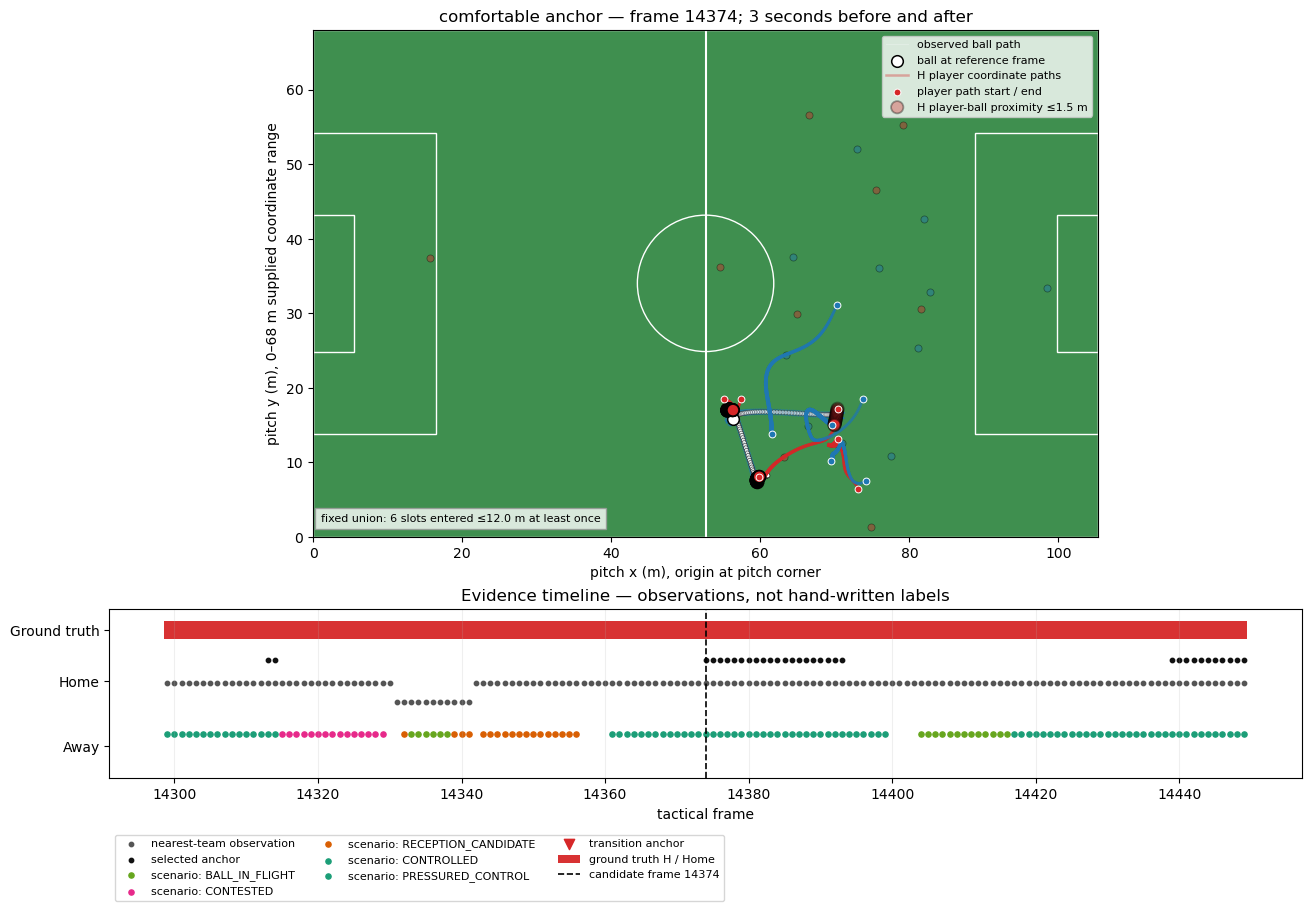

,frame,closest_team,closest_distance_m,team_distance_margin_m,candidate_pressure_m,candidate_opponent_density_5m,arrival_time_margin_s,ball_speed_derived_mps,scenario_context,selected_anchor_source,selected_anchor_confidence,genuine_reception_anchor,transition_anchor
14369,14369,H,1.350573,8.963039,11.220613,0.0,0.411909,1.090498,CONTROLLED,NO_ANCHOR,0.000000,False,False
14370,14370,H,1.377058,8.901746,11.163735,0.0,0.343244,0.849825,CONTROLLED,NO_ANCHOR,0.000000,False,False
14371,14371,H,1.402199,8.836586,11.106003,0.0,0.282222,0.650813,CONTROLLED,NO_ANCHOR,0.000000,False,False
14372,14372,H,1.420471,8.776182,11.024848,0.0,0.222489,0.462033,CONTROLLED,NO_ANCHOR,0.000000,False,False
14373,14373,H,1.433680,8.716511,10.849114,0.0,0.176682,0.343975,CONTROLLED,NO_ANCHOR,0.000000,False,False
14374,14374,H,1.440039,8.662215,10.673962,0.0,0.149642,0.327099,CONTROLLED,pressure_anchor_team,0.950000,False,False
14375,14375,H,1.439116,8.614603,10.498796,0.0,0.129307,0.403987,CONTROLLED,pressure_anchor_team,0.935620,False,False
14376,14376,H,1.429635,8.575895,10.323062,0.0,0.106568,0.546376,CONTROLLED,pressure_anchor_team,0.923369,False,False
14377,14377,H,1.413570,8.543905,10.148133,0.0,0.121362,0.656270,CONTROLLED,pressure_anchor_team,0.929446,False,False
14378,14378,H,1.390923,8.520492,9.973994,0.0,0.124408,0.757123,CONTROLLED,pressure_anchor_team,0.931137,False,False


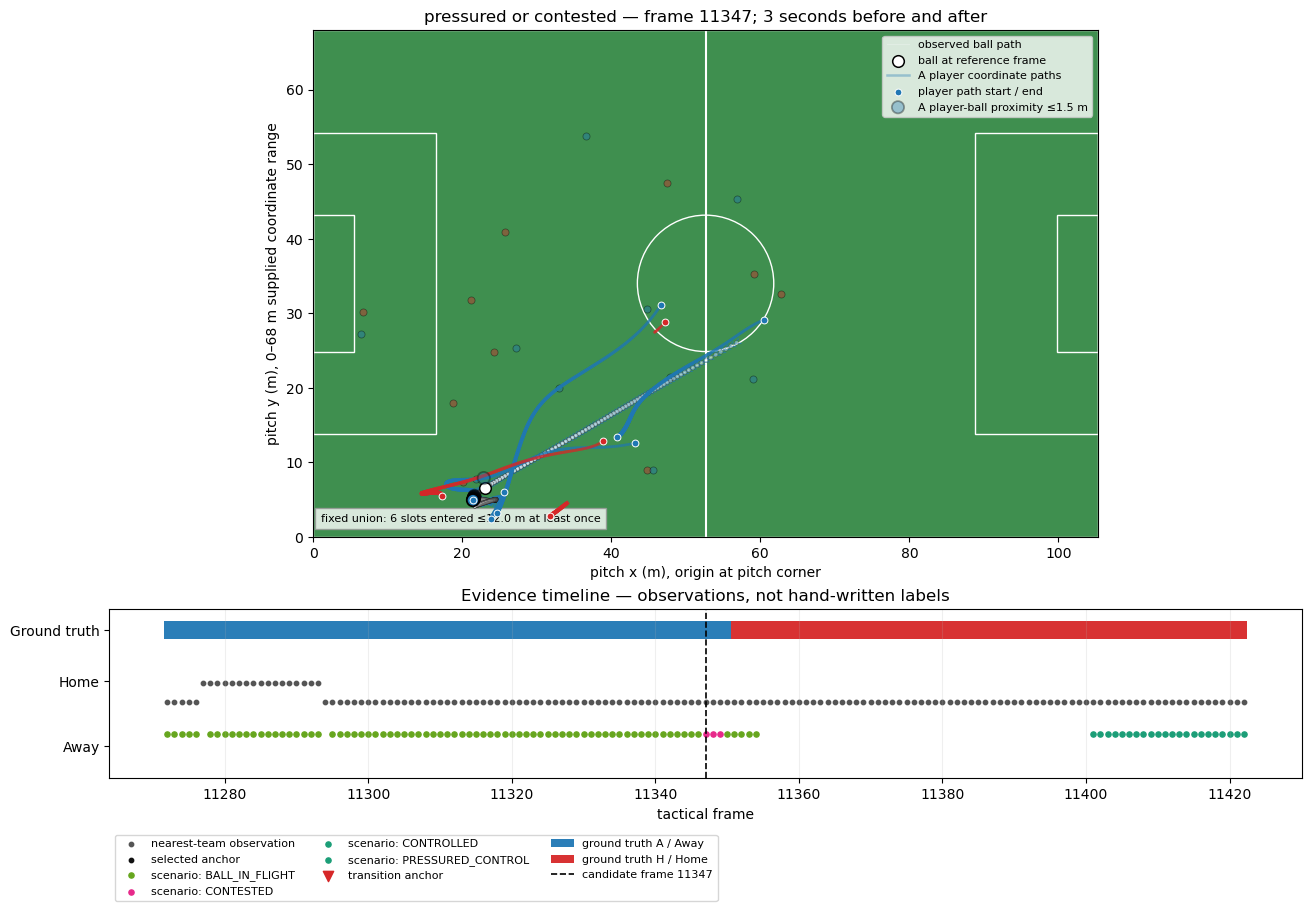

,frame,closest_team,closest_distance_m,team_distance_margin_m,candidate_pressure_m,candidate_opponent_density_5m,arrival_time_margin_s,ball_speed_derived_mps,scenario_context,selected_anchor_source,selected_anchor_confidence,genuine_reception_anchor,transition_anchor
11342,11342,A,1.517274,-1.636672,1.705795,1.0,-2.963226,10.409459,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11343,11343,A,1.497500,-1.595434,1.712809,1.0,-2.918427,9.911656,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11344,11344,A,1.513599,-1.541387,1.720131,1.0,-2.917817,9.355148,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11345,11345,A,1.557982,-1.481035,1.730950,1.0,-2.878907,8.795336,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11346,11346,A,1.629091,-1.417927,1.745631,1.0,-2.834256,8.177671,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11347,11347,A,1.720893,-1.356062,1.762810,1.0,-2.801243,7.583526,CONTESTED,NO_ANCHOR,0.0,False,False
11348,11348,A,1.829484,-1.298737,1.782934,1.0,-2.753584,6.928100,CONTESTED,NO_ANCHOR,0.0,False,False
11349,11349,A,1.951668,-1.249076,1.807208,1.0,-2.719608,6.262424,CONTESTED,NO_ANCHOR,0.0,False,False
11350,11350,A,2.083142,-1.208907,1.833760,1.0,-2.637768,5.642968,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11351,11351,A,2.223957,-1.180195,1.865168,1.0,-2.601167,4.964623,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False


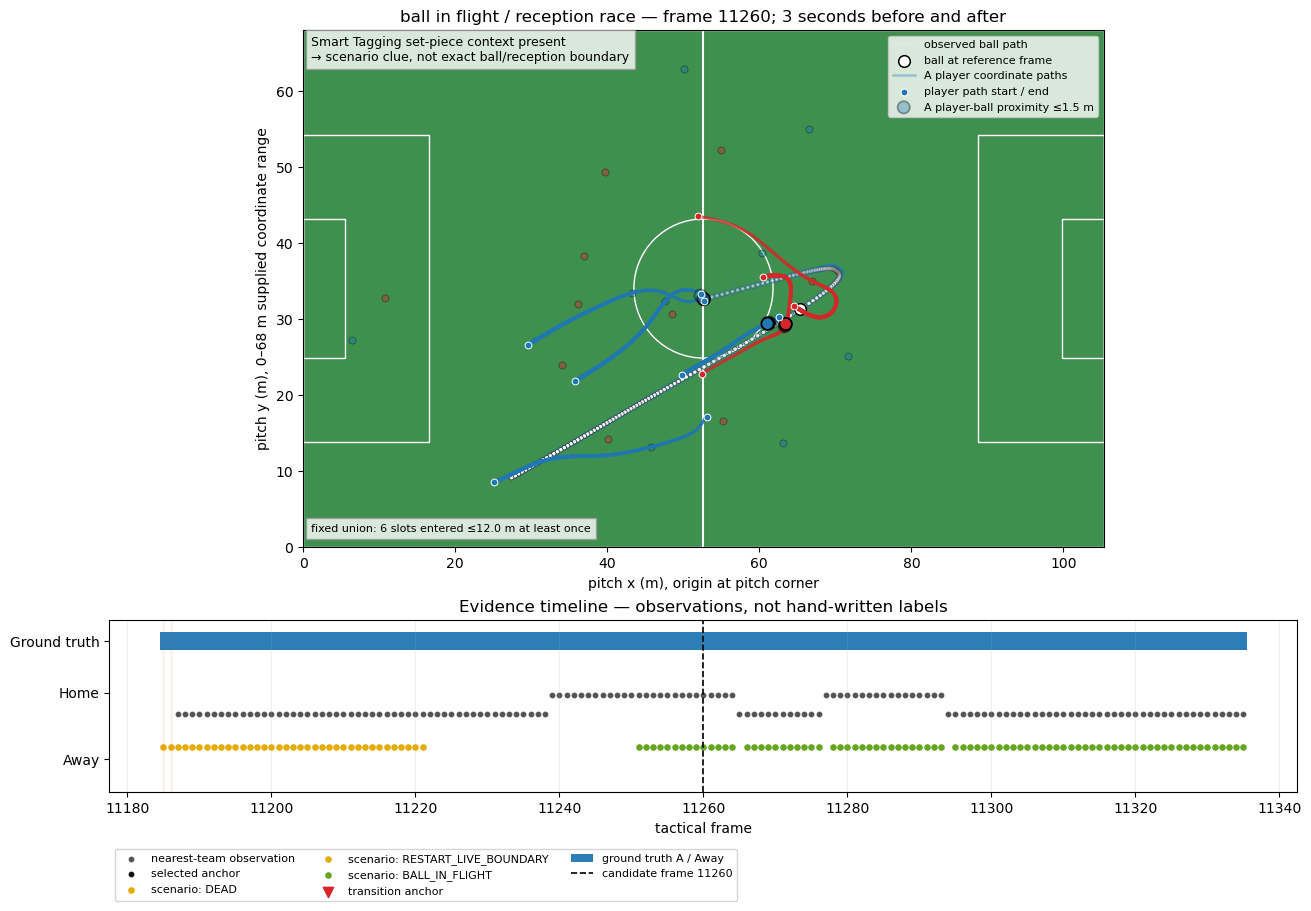

,frame,closest_team,closest_distance_m,team_distance_margin_m,candidate_pressure_m,candidate_opponent_density_5m,arrival_time_margin_s,ball_speed_derived_mps,scenario_context,selected_anchor_source,selected_anchor_confidence,genuine_reception_anchor,transition_anchor
11255,11255,H,3.368223,3.465490,6.179844,0.0,12.877696,12.823126,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11256,11256,H,3.133826,3.214939,6.442672,0.0,12.164206,13.910363,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11257,11257,H,3.062701,2.762350,6.706801,0.0,11.005454,14.957580,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11258,11258,H,3.193572,2.069593,6.972810,0.0,9.560199,16.008743,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11259,11259,H,3.529726,1.137546,7.238970,0.0,8.059205,16.955925,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11260,11260,H,3.430992,0.609599,1.714147,1.0,7.064402,17.863789,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11261,11261,H,2.578965,0.807253,1.775811,1.0,6.030015,18.710377,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11262,11262,H,1.726845,0.986428,1.856531,1.0,4.940240,19.441769,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11263,11263,H,0.960194,1.067890,1.954284,1.0,3.771342,20.111504,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11264,11264,H,0.789698,0.570192,2.070569,1.0,1.140384,20.625328,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False


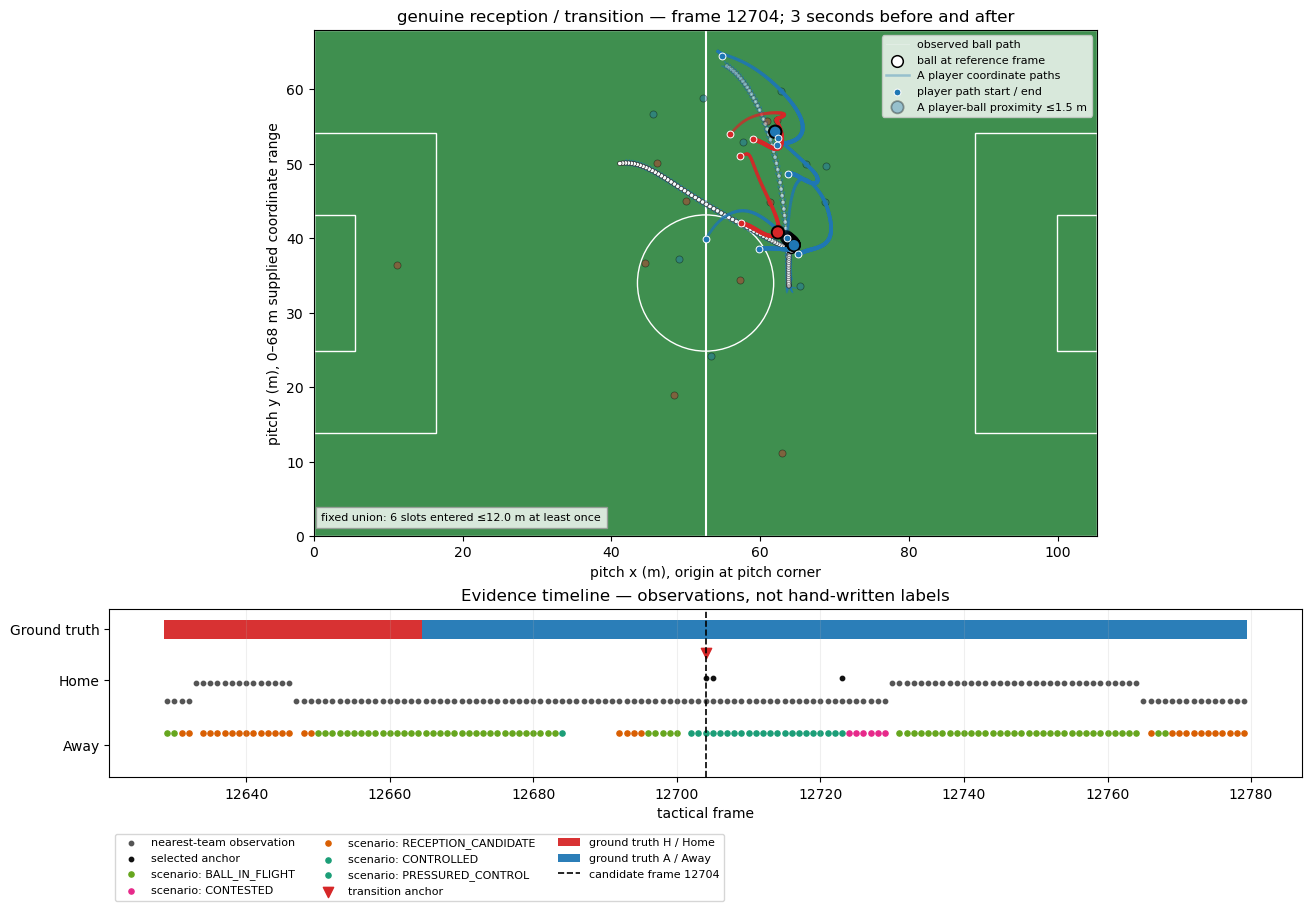

,frame,closest_team,closest_distance_m,team_distance_margin_m,candidate_pressure_m,candidate_opponent_density_5m,arrival_time_margin_s,ball_speed_derived_mps,scenario_context,selected_anchor_source,selected_anchor_confidence,genuine_reception_anchor,transition_anchor
12699,12699,A,3.205144,-4.953553,4.961363,1.0,-0.987344,5.527196,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
12700,12700,A,2.883942,-4.923027,4.930193,1.0,-0.986672,4.930544,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
12701,12701,A,2.592194,-4.887698,4.894497,1.0,-0.965078,4.318007,UNKNOWN,NO_ANCHOR,0.0,False,False
12702,12702,A,2.331038,-4.848152,4.854658,1.0,-0.951138,3.701182,PRESSURED_CONTROL,NO_ANCHOR,0.0,False,False
12703,12703,A,2.098152,-4.805127,4.811268,1.0,-0.942855,3.115554,PRESSURED_CONTROL,NO_ANCHOR,0.0,False,False
12704,12704,A,1.894235,-4.757749,4.763658,1.0,-0.928879,2.552112,CONTROLLED,anchor_team,1.0,False,True
12705,12705,A,1.717697,-4.706192,4.711523,1.0,-0.913582,2.020988,CONTROLLED,anchor_team,1.0,False,False
12706,12706,A,1.565779,-4.650290,4.654988,1.0,-0.896998,1.575031,CONTROLLED,NO_ANCHOR,0.0,False,False
12707,12707,A,1.438463,-4.591393,4.595096,1.0,-0.889541,1.196882,CONTROLLED,NO_ANCHOR,0.0,False,False
12708,12708,A,1.330930,-4.527872,4.530475,1.0,-0.865533,0.970859,CONTROLLED,NO_ANCHOR,0.0,False,False


In [9]:
# Purpose: plot data-selected examples for the main unresolved anchors and scenarios.
def _first_frame(mask, lo=PUBLIC_START + 75, hi=PUBLIC_END - 75):
    mask = pd.Series(mask, index=features.index).fillna(False).astype(bool)
    candidates = features.loc[mask & features.frame.between(lo, hi), 'frame']
    return int(candidates.iloc[0]) if not candidates.empty else None

case_masks = {
    'comfortable anchor': features.get('low_pressure_control', pd.Series(False, index=features.index)) & features.get('selected_anchor_team', pd.Series(index=features.index)).notna(),
    'pressured or contested': features.get('scenario_context', pd.Series('', index=features.index)).isin(['CONTESTED', 'PRESSURED_CONTROL']),
    'ball in flight / reception race': features.get('scenario_context', pd.Series('', index=features.index)).eq('BALL_IN_FLIGHT'),
    'genuine reception / transition': features.get('genuine_reception_anchor', pd.Series(False, index=features.index)) | features.get('transition_anchor', pd.Series(False, index=features.index)),
}
case_frames = {name: _first_frame(mask) for name, mask in case_masks.items()}
display(pd.DataFrame({'case': case_frames.keys(), 'representative_frame': case_frames.values()}))
for name, centre in case_frames.items():
    if centre is None:
        print(f'{name}: no data-selected example in the public window')
        continue
    fig, axes = plot_evidence_window(features, centre - 75, centre + 75, team_by_slot=team_by_slot, ground_truth=gt_by_frame)
    axes[0].set_title(f'{name} — frame {centre}; 3 seconds before and after')
    axes[1].axvline(centre, color='black', ls='--', lw=1.2, label=f'candidate frame {centre}')
    axes[1].legend(loc='upper left', bbox_to_anchor=(0, -0.30), ncol=3, fontsize=8)
    plt.show()
    cols = [c for c in ['frame','closest_team','closest_distance_m','team_distance_margin_m','candidate_pressure_m','candidate_opponent_density_5m','arrival_time_margin_s','ball_speed_derived_mps','scenario_context','selected_anchor_source','selected_anchor_confidence','genuine_reception_anchor','transition_anchor'] if c in features]
    display(features.loc[features.frame.between(centre-5, centre+5), cols])

## Goal-kick scenario — speed signature

- Select the first Smart Tagging `SET PIECES` interval whose type is `Goal Kick`.
- Plot only the measured 2D ball speed and acceleration around that restart.
- Look for: slow stationary setup → sharp acceleration after the kick → deceleration toward the receiving phase.
- This is a restart signature, not proof of ball height or exact foot contact.

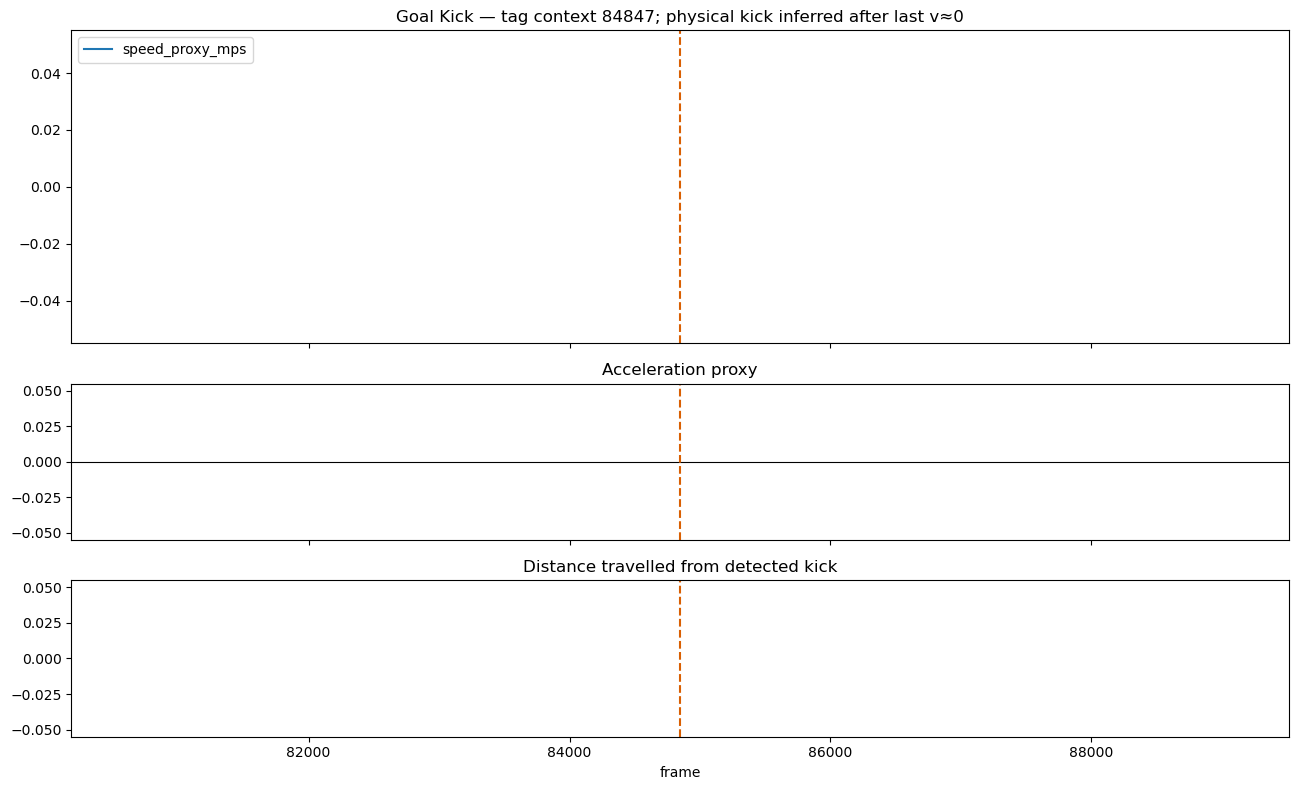

In [10]:
goal_kicks = [tag for tag in smart_tags if tag.get('code') == 'SET PIECES' and tag.get('tags', {}).get('Type') == 'Goal Kick']
if not goal_kicks:
    print('No goal-kick tag found.')
else:
    tag_frame = int(goal_kicks[0]['start_frame'])
    local = features.loc[features.frame.between(tag_frame - 50, tag_frame + 125)].copy()
    local['speed_proxy_mps'] = np.hypot(local.ball_x.diff()*PITCH_LENGTH_M, local.ball_y.diff()*PITCH_WIDTH_M) * 25
    local['acceleration_proxy_mps2'] = local.speed_proxy_mps.diff() * 25
    local['distance_step_m'] = np.hypot(local.ball_x.diff()*PITCH_LENGTH_M, local.ball_y.diff()*PITCH_WIDTH_M)
    near_zero = local.loc[local.frame.between(tag_frame - 10, tag_frame + 75) & local.speed_proxy_mps.le(0.5)]
    last_zero_frame = int(near_zero.frame.iloc[-1]) if not near_zero.empty else None
    movement_start = last_zero_frame if last_zero_frame is not None else tag_frame
    kick_candidates = local.loc[local.frame.gt(movement_start) & local.acceleration_proxy_mps2.notna()]
    kick_row = kick_candidates.iloc[kick_candidates.acceleration_proxy_mps2.argmax()] if not kick_candidates.empty else None
    kick_frame = None if kick_row is None else int(kick_row.frame)
    kick_speed = None if kick_row is None else float(kick_row.speed_proxy_mps)
    kick_accel = None if kick_row is None else float(kick_row.acceleration_proxy_mps2)
    kick_mask = local.frame.ge(kick_frame) if kick_frame is not None else pd.Series(False, index=local.index)
    local['distance_from_kick_m'] = local.distance_step_m.where(kick_mask, 0).fillna(0).cumsum()
    fig, (ax_speed, ax_accel, ax_dist) = plt.subplots(3, 1, figsize=(13, 8), sharex=True, gridspec_kw={'height_ratios':[2,1,1]})
    local.plot(x='frame', y='speed_proxy_mps', ax=ax_speed, legend=False, title=f'Goal Kick — tag context {tag_frame}; physical kick inferred after last v≈0')
    local.plot(x='frame', y='acceleration_proxy_mps2', ax=ax_accel, legend=False, color='#7b3294', title='Acceleration proxy')
    local.plot(x='frame', y='distance_from_kick_m', ax=ax_dist, legend=False, color='#111111', title='Distance travelled from detected kick')
    ax_accel.axhline(0, color='black', linewidth=.8)
    for axis in (ax_speed, ax_accel, ax_dist): axis.axvline(tag_frame, color='#d95f02', linewidth=1.5, ls='--')
    if last_zero_frame is not None:
        ax_speed.axvline(last_zero_frame, color='#555555', linewidth=1.5, ls=':', label=f'last v≈0 {last_zero_frame}')
        ax_accel.axvline(last_zero_frame, color='#555555', linewidth=1.5, ls=':')
        ax_dist.axvline(last_zero_frame, color='#555555', linewidth=1.5, ls=':')
    if kick_frame is not None:
        for axis in (ax_speed, ax_accel, ax_dist): axis.axvline(kick_frame, color='#2ca02c', linewidth=1.5, ls='-.')
        ax_speed.annotate(f'kick departure / max dv/dt\n{kick_frame}\n{kick_speed:.1f} m/s; {kick_accel:.1f} m/s²', (kick_frame, kick_speed), xytext=(8, 8), textcoords='offset points', fontsize=8, color='#2ca02c', arrowprops={'arrowstyle':'->', 'color':'#2ca02c'})
    ax_speed.legend(loc='upper left'); plt.tight_layout(); plt.show()

## Dead-ball restart study — zero speed → first live possession

- Candidates: Smart Tagging restart types plus offside
- Signal: measured 2D ball-speed proxy; exact zero where present, otherwise near-zero ≤ 0.5 m/s
- Delay: zero/near-zero frame → first public H/A frame
- Post-goal kickoff: once the ball shows sustained movement, kickoff-side possession is a direct H/A anchor
- Outside public interval: keep trajectory evidence; report ground-truth timing as unavailable
- Short restart: small speed spike; long restart: large speed hike and longer reception delay

,kind,tag_frame,tag_type,candidate_source
0,Free Kick,17533,Free Kick,Smart Tagging
1,Goal Kick,18320,Goal Kick,Smart Tagging
2,Untagged restart-like,11396,v≈0 → movement,trajectory fallback


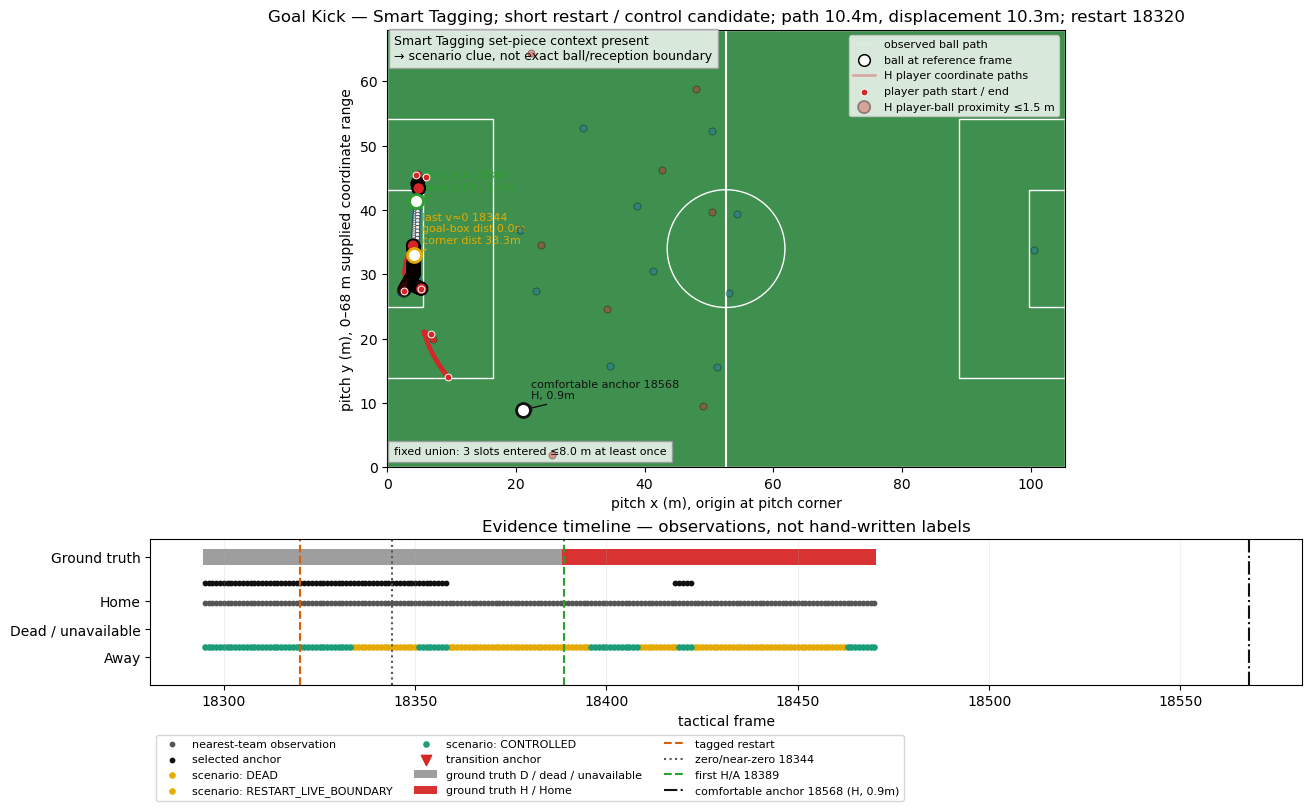

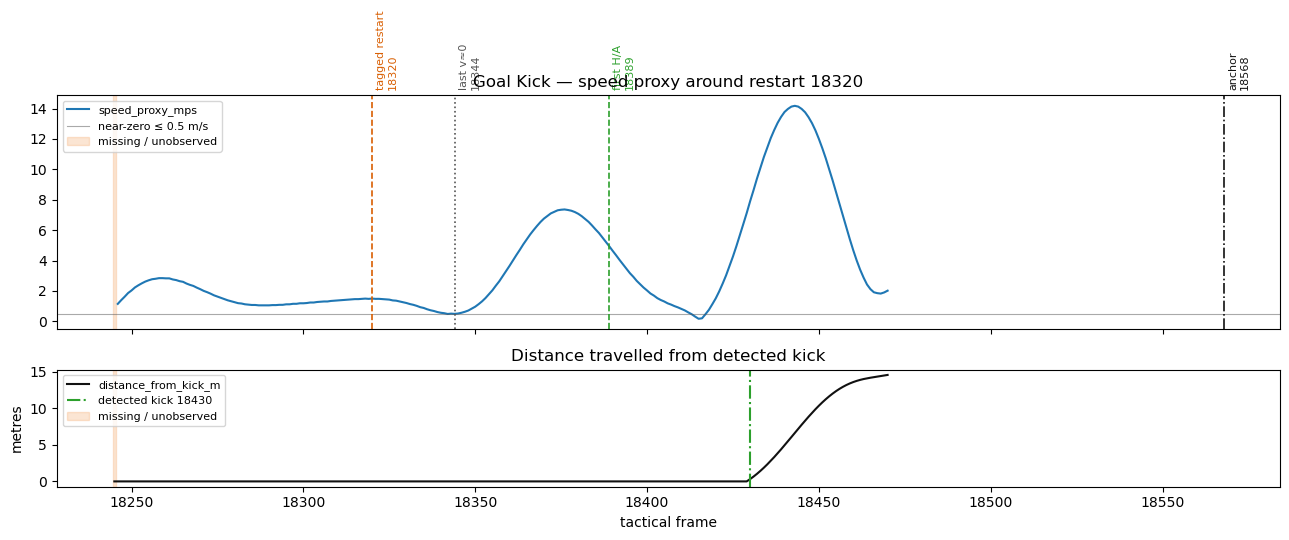

/var/folders/hx/0wt7j0md7ld6cq4m77bhf6w80000gn/T/vscode-agent-codex-sandbox-ppwJ0N/ipykernel_71045/2895941894.py:201: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()


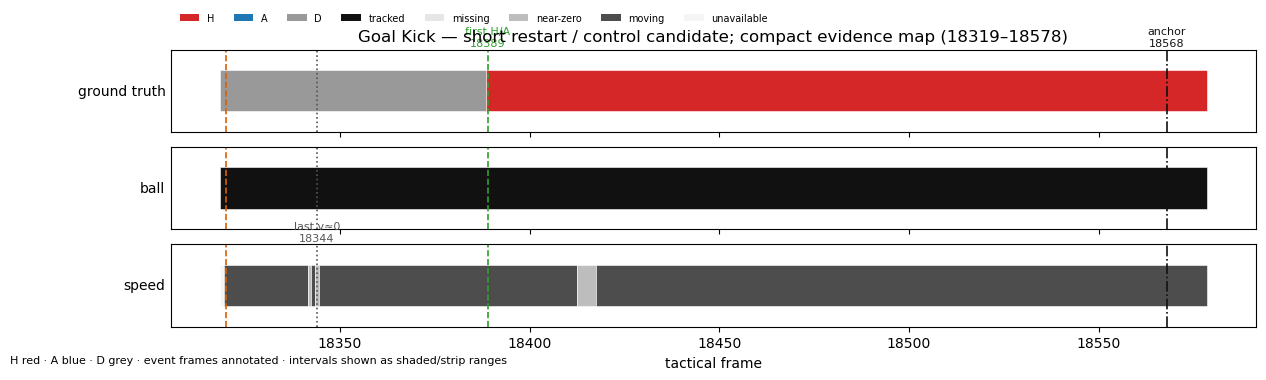

Corner Kick: no public candidate
Throw-in: no public candidate


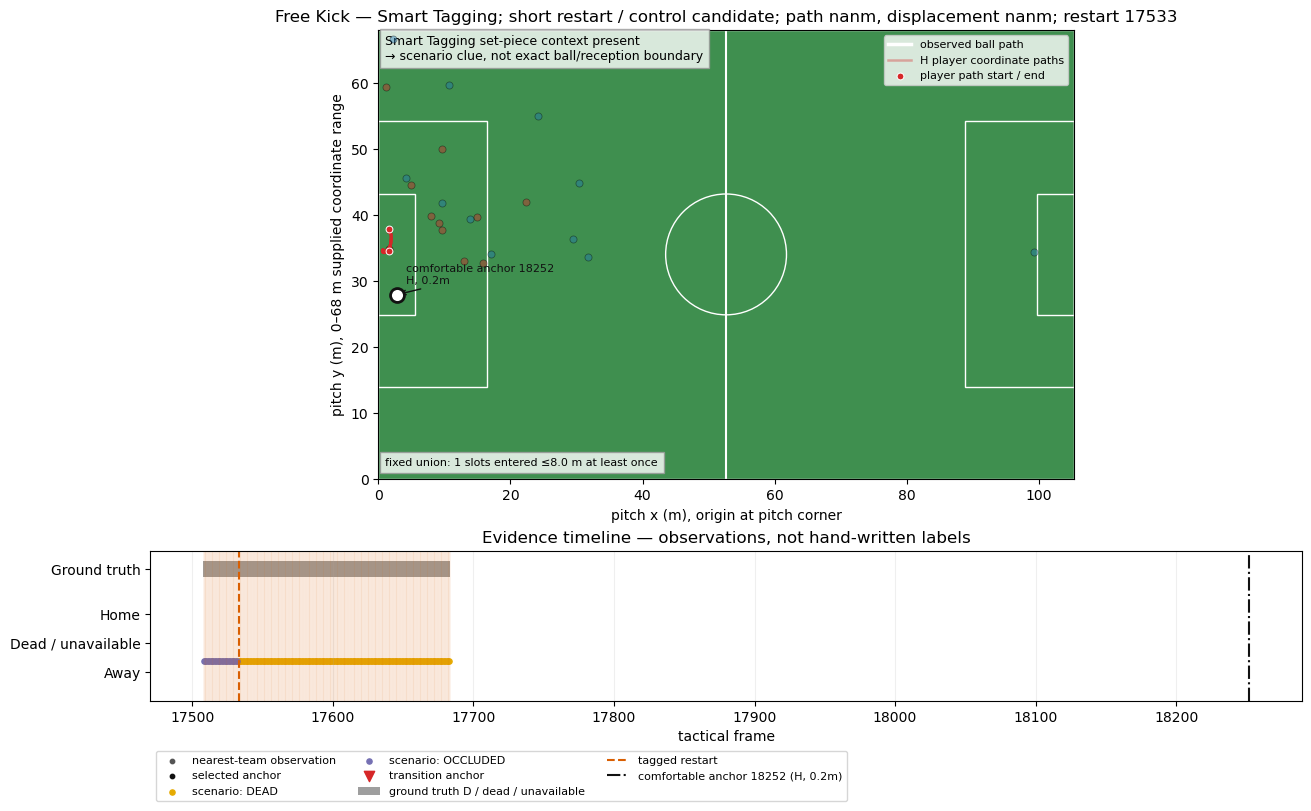

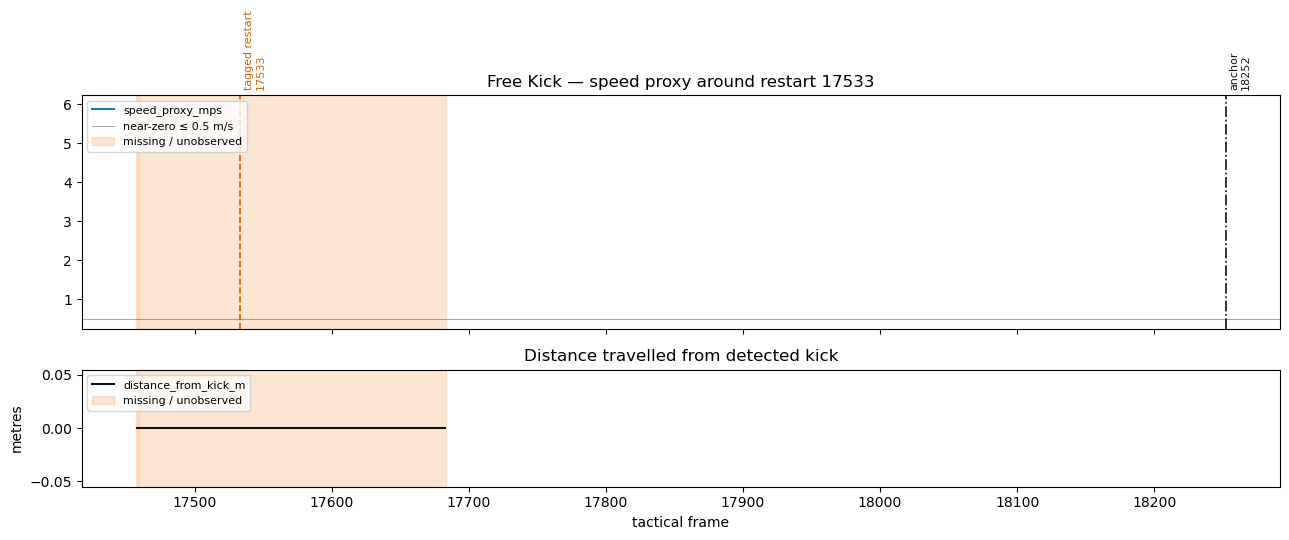

/var/folders/hx/0wt7j0md7ld6cq4m77bhf6w80000gn/T/vscode-agent-codex-sandbox-ppwJ0N/ipykernel_71045/2895941894.py:201: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()


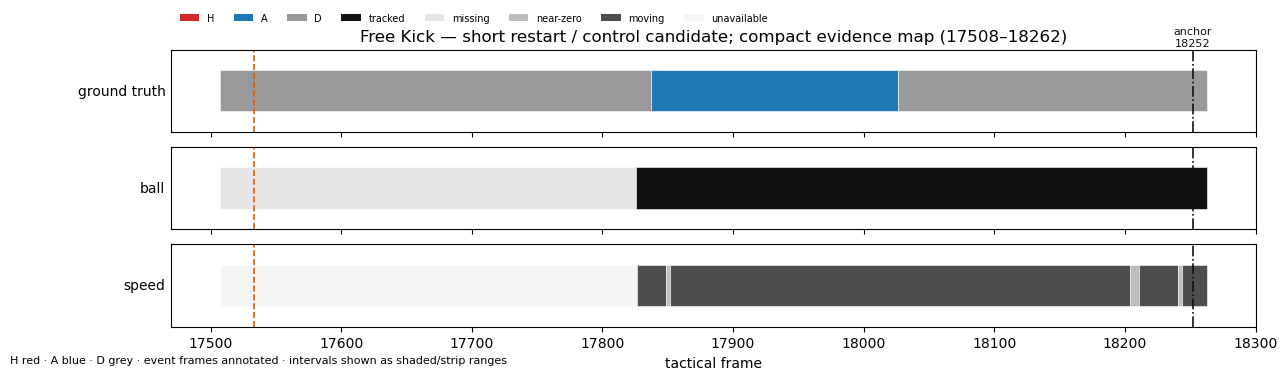

Offside: no public candidate


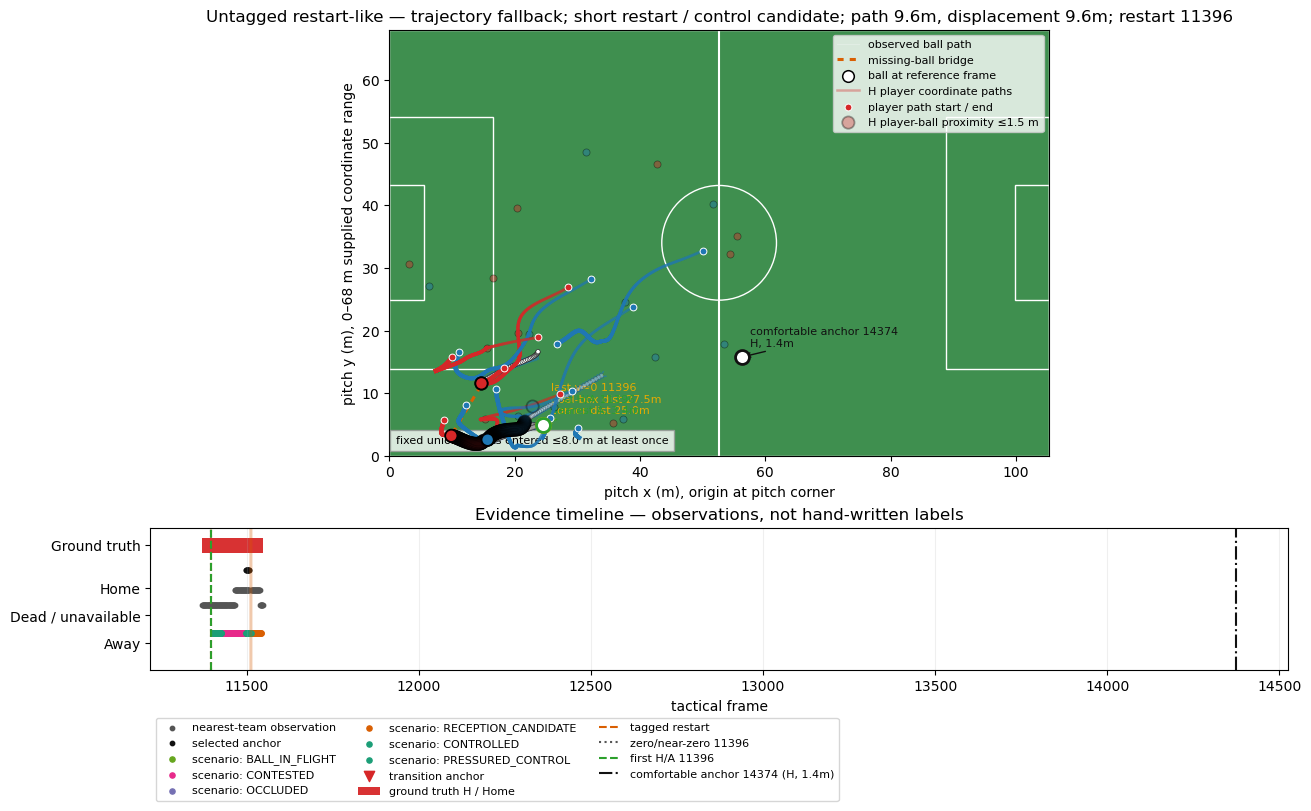

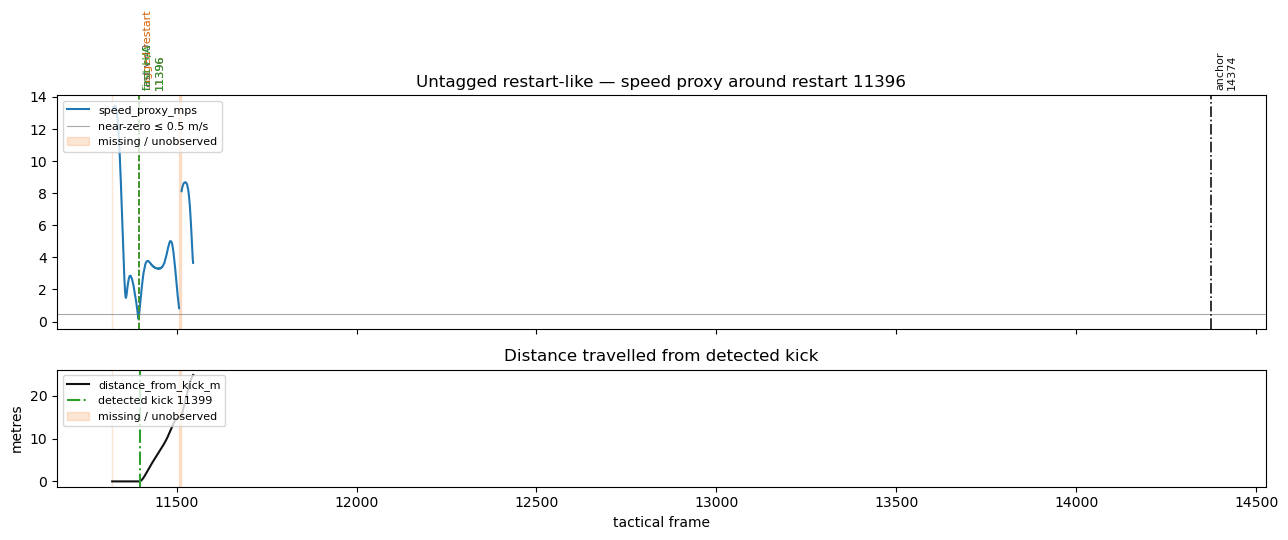

/var/folders/hx/0wt7j0md7ld6cq4m77bhf6w80000gn/T/vscode-agent-codex-sandbox-ppwJ0N/ipykernel_71045/2895941894.py:201: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()


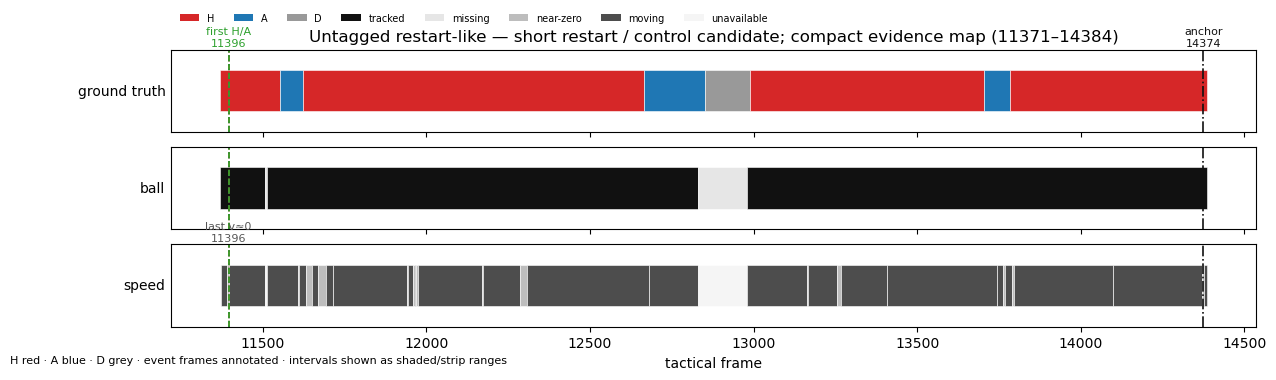

,kind,candidate_source,tag_frame,tag_validation,tag_speed_mps,public_ground_truth_available,path_class,max_post_zero_speed_mps,ball_path_distance_m,straight_displacement_m,...,corner_proximity_m,D_end,first_H_or_A,first_H_or_A_nearest_team,first_H_or_A_nearest_distance_m,anchor_frame,anchor_team,anchor_nearest_distance_m,D_to_live_frames,D_to_live_seconds
0,Goal Kick,Smart Tagging,18320,Smart Tag candidate only — v≈0/location test n...,1.499706,True,short restart / control candidate,7.362892,10.411520,10.277478,...,33.338196,18388.0,18389.0,H,3.561269,18568,H,0.934651,45.0,1.8
1,Free Kick,Smart Tagging,17533,Smart Tag candidate only — v≈0/location test n...,NaN,True,short restart / control candidate,NaN,NaN,NaN,...,NaN,17733.0,NaN,None,NaN,18252,H,0.184033,NaN,NaN
2,Untagged restart-like,trajectory fallback,11396,Smart Tag candidate only — v≈0/location test n...,0.476602,True,short restart / control candidate,3.949182,9.592209,9.575655,...,24.997906,NaN,11396.0,A,3.374576,14374,H,1.440039,0.0,0.0


In [11]:
# Data-selected restart audit; no hand-written frames.
restart_types = ['Goal Kick', 'Corner Kick', 'Throw-in', 'Free Kick', 'Offside']
# This notebook is restricted to the five-minute public-label interval.
# Every scenario comparison below therefore has valid H/A/D ground truth.
lo, hi = PUBLIC_START, PUBLIC_END
rows = []
for tag in smart_tags:
    code_name = str(tag.get('code', '')); tag_type = str(tag.get('tags', {}).get('Type', '')).strip()
    norm = tag_type.lower().replace('_', ' ').replace('-', ' ')
    if code_name == 'SET PIECES' and 'goal' in norm and 'kick' in norm: kind = 'Goal Kick'
    elif code_name == 'SET PIECES' and 'corner' in norm: kind = 'Corner Kick'
    elif code_name == 'SET PIECES' and 'throw' in norm: kind = 'Throw-in'
    elif code_name == 'SET PIECES' and 'free' in norm and 'kick' in norm: kind = 'Free Kick'
    elif 'offside' in (code_name + ' ' + norm).lower(): kind = 'Offside'
    else: continue
    a, b = int(tag['start_frame']), int(tag['end_frame'])
    if lo <= a <= hi: rows.append({'kind': kind, 'tag_frame': a, 'tag_type': tag_type})
restart_candidates = pd.DataFrame(rows).sort_values(['kind', 'tag_frame']) if rows else pd.DataFrame()
# Do not suppress the physical study when a Smart Tag has no public candidate.
# Scan for a generic restart-like episode: a sustained near-zero ball speed
# followed by live movement.  This is deliberately unresolved as corner/free
# kick type; the speed, path, distance, and H/A evidence remain useful.
public_scan = features.loc[features.frame.between(lo, hi)].copy()
public_scan['speed_proxy_mps'] = np.hypot(public_scan.ball_x.diff()*PITCH_LENGTH_M, public_scan.ball_y.diff()*PITCH_WIDTH_M)*25
near_zero = public_scan.speed_proxy_mps.le(0.5) & public_scan.speed_proxy_mps.notna()
fallback_rows = []
run_start = None
for row in public_scan.loc[near_zero, ['frame']].itertuples(index=False):
    frame_value = int(row.frame)
    if run_start is None: run_start = frame_value
    elif frame_value > prev_frame + 1:
        if prev_frame - run_start + 1 >= 3:
            forward = public_scan.loc[public_scan.frame.between(prev_frame, min(prev_frame+50, hi))]
            moving = forward.loc[forward.speed_proxy_mps.ge(2)]
            if not moving.empty: fallback_rows.append({'kind': 'Untagged restart-like', 'tag_frame': prev_frame, 'tag_type': 'v≈0 → movement', 'candidate_source': 'trajectory fallback'})
        run_start = frame_value
    prev_frame = frame_value
if run_start is not None and 'prev_frame' in locals() and prev_frame - run_start + 1 >= 3:
    forward = public_scan.loc[public_scan.frame.between(prev_frame, min(prev_frame+50, hi))]
    if not forward.loc[forward.speed_proxy_mps.ge(2)].empty: fallback_rows.append({'kind': 'Untagged restart-like', 'tag_frame': prev_frame, 'tag_type': 'v≈0 → movement', 'candidate_source': 'trajectory fallback'})
if fallback_rows:
    fallback = pd.DataFrame(fallback_rows).drop_duplicates('tag_frame').sort_values('tag_frame')
    if restart_candidates.empty: restart_candidates = fallback
    elif not restart_candidates.kind.eq('Untagged restart-like').any(): restart_candidates = pd.concat([restart_candidates, fallback.iloc[[0]]], ignore_index=True)
if not restart_candidates.empty:
    if 'candidate_source' not in restart_candidates: restart_candidates['candidate_source'] = 'Smart Tagging'
    restart_candidates['candidate_source'] = restart_candidates['candidate_source'].fillna('Smart Tagging')
display(restart_candidates)
results = []
audit_kinds = restart_types + (['Untagged restart-like'] if not restart_candidates.empty and restart_candidates.kind.eq('Untagged restart-like').any() else [])
for kind in audit_kinds:
    cand = restart_candidates.loc[restart_candidates.kind.eq(kind)] if not restart_candidates.empty else pd.DataFrame()
    if cand.empty: print(f'{kind}: no public candidate'); continue
    centre = int(cand.iloc[0].tag_frame); candidate_source = str(cand.iloc[0].get('candidate_source', 'Smart Tagging')); local = features.loc[features.frame.between(centre-75, centre+150)].copy()
    local['speed_proxy_mps'] = np.hypot(local.ball_x.diff()*PITCH_LENGTH_M, local.ball_y.diff()*PITCH_WIDTH_M)*25
    local['acceleration_proxy_mps2'] = local.speed_proxy_mps.diff()*25
    local['distance_step_m'] = np.hypot(local.ball_x.diff()*PITCH_LENGTH_M, local.ball_y.diff()*PITCH_WIDTH_M)
    public_gt_available = True
    gt = gt_by_frame.reindex(range(centre, min(centre+200, PUBLIC_END)+1)).dropna()
    live = gt.loc[gt.isin(['H','A'])]
    live_frame = int(live.index[0]) if not live.empty else None; d = gt.loc[gt.eq('D')]
    z_end = live_frame if live_frame is not None else centre + 75
    z = local.loc[local.frame.between(centre-25, z_end) & local.speed_proxy_mps.notna() & local.speed_proxy_mps.le(0.5)]
    # Operational restart point: last observed zero/near-zero frame before the first public H/A transition.
    zero_frame = int(z.iloc[-1].frame) if not z.empty else None
    kick_candidates = local.loc[local.frame.gt(zero_frame if zero_frame is not None else centre) & local.acceleration_proxy_mps2.notna()]
    kick_row = kick_candidates.iloc[kick_candidates.acceleration_proxy_mps2.argmax()] if not kick_candidates.empty else None
    kick_frame = None if kick_row is None else int(kick_row.frame)
    kick_mask = local.frame.ge(kick_frame) if kick_frame is not None else pd.Series(False, index=local.index)
    local['distance_from_kick_m'] = local.distance_step_m.where(kick_mask, 0).fillna(0).cumsum()
    tag_row = local.loc[local.frame.eq(centre)].iloc[0] if not local.loc[local.frame.eq(centre)].empty else None
    tag_speed = None if tag_row is None else float(local.loc[local.frame.eq(centre), 'speed_proxy_mps'].iloc[0])
    zero_row = local.loc[local.frame.eq(zero_frame)].iloc[0] if zero_frame is not None and not local.loc[local.frame.eq(zero_frame)].empty else None
    zero_x_m = None if zero_row is None or pd.isna(zero_row.ball_x) else float(zero_row.ball_x * PITCH_LENGTH_M)
    zero_y_m = None if zero_row is None or pd.isna(zero_row.ball_y) else float(zero_row.ball_y * PITCH_WIDTH_M)
    goal_line_distance_m = None if zero_x_m is None else min(zero_x_m, PITCH_LENGTH_M - zero_x_m)
    goal_box_y_min, goal_box_y_max = (PITCH_WIDTH_M - 18.32) / 2, (PITCH_WIDTH_M + 18.32) / 2
    goal_box_x_depth = 5.5
    goal_box_compatible = (zero_x_m is not None and zero_y_m is not None and (zero_x_m <= goal_box_x_depth or zero_x_m >= PITCH_LENGTH_M - goal_box_x_depth) and goal_box_y_min <= zero_y_m <= goal_box_y_max)
    if zero_x_m is None or zero_y_m is None:
        goal_box_proximity_m = corner_proximity_m = np.nan
    else:
        dx_box = 0 if zero_x_m <= goal_box_x_depth or zero_x_m >= PITCH_LENGTH_M - goal_box_x_depth else min(zero_x_m - goal_box_x_depth, (PITCH_LENGTH_M - goal_box_x_depth) - zero_x_m)
        dy_box = 0 if goal_box_y_min <= zero_y_m <= goal_box_y_max else min(abs(zero_y_m - goal_box_y_min), abs(zero_y_m - goal_box_y_max))
        goal_box_proximity_m = float(np.hypot(max(dx_box, 0), max(dy_box, 0)))
        corner_proximity_m = float(min(np.hypot(zero_x_m - cx, zero_y_m - cy) for cx in (0, PITCH_LENGTH_M) for cy in (0, PITCH_WIDTH_M)))
    corner_geometry = corner_proximity_m <= 3.0 if pd.notna(corner_proximity_m) else False
    goal_kick_supported = tag_speed is not None and tag_speed <= 0.5 and goal_box_compatible
    tag_validation = 'supported by v≈0 + goal-line location' if goal_kick_supported else 'Smart Tag candidate only — v≈0/location test not jointly satisfied'
    delay = None if zero_frame is None or live_frame is None else live_frame-zero_frame
    post_zero = local.loc[local.frame.ge(zero_frame if zero_frame is not None else centre) & local.speed_proxy_mps.notna()].head(75)
    max_speed = float(post_zero.speed_proxy_mps.max()) if not post_zero.empty else np.nan
    if len(post_zero) >= 2:
        dx = post_zero.ball_x.diff() * PITCH_LENGTH_M
        dy = post_zero.ball_y.diff() * PITCH_WIDTH_M
        path_distance = float(np.hypot(dx, dy).sum())
        straight_displacement = float(np.hypot((post_zero.ball_x.iloc[-1]-post_zero.ball_x.iloc[0])*PITCH_LENGTH_M, (post_zero.ball_y.iloc[-1]-post_zero.ball_y.iloc[0])*PITCH_WIDTH_M))
    else:
        path_distance = straight_displacement = np.nan
    path_class = 'long-ball candidate' if (max_speed >= 15 or path_distance >= 20 or straight_displacement >= 20) else 'short restart / control candidate'
    anchor_mask = features.frame.ge(centre) & features.get('low_pressure_control', pd.Series(False, index=features.index)).fillna(False) & features.get('selected_anchor_team', pd.Series(index=features.index)).notna()
    anchor_rows = features.loc[anchor_mask].sort_values('frame')
    anchor_row = anchor_rows.iloc[0] if not anchor_rows.empty else None
    anchor_frame = None if anchor_row is None else int(anchor_row.frame)
    anchor_team = None if anchor_row is None else anchor_row.selected_anchor_team
    anchor_distance = None if anchor_row is None else float(anchor_row.closest_distance_m)
    live_row = features.loc[features.frame.eq(live_frame)].iloc[0] if live_frame is not None and not features.loc[features.frame.eq(live_frame)].empty else None
    live_team = None if live_row is None else live_row.closest_team
    live_distance = None if live_row is None else float(live_row.closest_distance_m)
    results.append({'kind': kind, 'candidate_source': candidate_source, 'tag_frame': centre, 'tag_validation': tag_validation, 'tag_speed_mps': tag_speed, 'public_ground_truth_available': public_gt_available, 'path_class': path_class, 'max_post_zero_speed_mps': max_speed, 'ball_path_distance_m': path_distance, 'straight_displacement_m': straight_displacement, 'zero_or_near_zero': zero_frame, 'zero_x_m': zero_x_m, 'zero_y_m': zero_y_m, 'goal_line_distance_m': goal_line_distance_m, 'goal_box_compatible': goal_box_compatible, 'goal_box_proximity_m': goal_box_proximity_m, 'corner_geometry': corner_geometry, 'corner_proximity_m': corner_proximity_m, 'D_end': int(d.index[-1]) if not d.empty else None, 'first_H_or_A': live_frame, 'first_H_or_A_nearest_team': live_team, 'first_H_or_A_nearest_distance_m': live_distance, 'anchor_frame': anchor_frame, 'anchor_team': anchor_team, 'anchor_nearest_distance_m': anchor_distance, 'D_to_live_frames': delay, 'D_to_live_seconds': None if delay is None else delay/25})
    fig, (pax, tax) = plt.subplots(2, 1, figsize=(13, 8), gridspec_kw={'height_ratios':[3,1]}, constrained_layout=True)
    plot_trajectory_window(features, centre-75, centre+150, team_by_slot=team_by_slot, reference_frame=centre, nearby_radius_m=8.0, nearby_count=None, show_all_reference_players=True, ax=pax)
    pax.set_title(f'{kind} — {candidate_source}; {path_class}; path {path_distance:.1f}m, displacement {straight_displacement:.1f}m; restart {centre}')
    zero_label = f'last v≈0 {zero_frame}\ngoal-box dist {goal_box_proximity_m:.1f}m\ncorner dist {corner_proximity_m:.1f}m' if zero_row is not None else None
    for point_row, label, color in ((zero_row, zero_label, '#e6ab02'), (live_row, f'first H/A {live_frame}\nnearest {live_team}, {live_distance:.1f}m' if live_row is not None else None, '#2ca02c'), (anchor_row, f'comfortable anchor {anchor_frame}\n{anchor_team}, {anchor_distance:.1f}m' if anchor_row is not None else None, '#111111')):
        if point_row is not None and pd.notna(point_row.ball_x) and pd.notna(point_row.ball_y):
            pax.scatter([point_row.ball_x * PITCH_LENGTH_M], [point_row.ball_y * PITCH_WIDTH_M], s=100, facecolor='white', edgecolor=color, linewidth=2, zorder=8)
            pax.annotate(label, (point_row.ball_x * PITCH_LENGTH_M, point_row.ball_y * PITCH_WIDTH_M), xytext=(6, 8), textcoords='offset points', fontsize=8, color=color, arrowprops={'arrowstyle':'->', 'color':color})
    plot_timeline_window(features, centre-25, min(hi, centre+150), ground_truth=gt_by_frame if public_gt_available else None, ax=tax)
    tax.axvline(centre, color='#d95f02', ls='--', label='tagged restart')
    if zero_frame is not None: tax.axvline(zero_frame, color='#555', ls=':', label=f'zero/near-zero {zero_frame}')
    if live_frame is not None: tax.axvline(live_frame, color='#2ca02c', ls='--', label=f'first H/A {live_frame}')
    if anchor_frame is not None: tax.axvline(anchor_frame, color='#111111', ls='-.', label=f'comfortable anchor {anchor_frame} ({anchor_team}, {anchor_distance:.1f}m)')
    tax.legend(loc='upper left', bbox_to_anchor=(0,-.30), ncol=3, fontsize=8); plt.show()
    fig, (sax, dax) = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True, gridspec_kw={'height_ratios':[2,1]})
    local.plot(x='frame', y='speed_proxy_mps', ax=sax, legend=False, title=f'{kind} — speed proxy around restart {centre}')
    local.plot(x='frame', y='distance_from_kick_m', ax=dax, legend=False, color='#111111', title='Distance travelled from detected kick')
    if kick_frame is not None: dax.axvline(kick_frame, color='#2ca02c', ls='-.', label=f'detected kick {kick_frame}')
    if not local.speed_proxy_mps.notna().any():
        sax.text(0.5, 0.5, 'ball speed unavailable — supplied ball coordinates are missing in this window', transform=sax.transAxes, ha='center', va='center', color='#a33')
        sax.set_ylim(0, 1); dax.set_ylim(0, 1)
    sax.axhline(.5, color='#555', alpha=.5, lw=.8, label='near-zero ≤ 0.5 m/s')
    # Ranges are shaded and explained in the legend; point events are annotated on-plot.
    missing = local.frame[local.speed_proxy_mps.isna()].to_numpy()
    if len(missing):
        starts = [missing[0]]; ends = []
        for prev, cur in zip(missing[:-1], missing[1:]):
            if cur != prev + 1: ends.append(prev); starts.append(cur)
        ends.append(missing[-1])
        for i, (start, end) in enumerate(zip(starts, ends)):
            for axis in (sax, dax): axis.axvspan(start - .5, end + .5, color='#f4a261', alpha=.28, label='missing / unobserved' if i == 0 else None)
    sax.axvline(centre, color='#d95f02', ls='--', lw=1.2)
    if zero_frame is not None:
        sax.axvline(zero_frame, color='#555', ls=':', lw=1.2)
    if live_frame is not None:
        sax.axvline(live_frame, color='#2ca02c', ls='--', lw=1.2)
    if anchor_frame is not None:
        sax.axvline(anchor_frame, color='#111', ls='-.', lw=1.2)
    event_labels = [(centre, 'tagged restart', '#d95f02'), (zero_frame, 'last v≈0', '#555'), (live_frame, 'first H/A', '#2ca02c'), (anchor_frame, 'anchor', '#111')]
    for frame_value, label, colour in event_labels:
        if frame_value is not None: sax.annotate(f'{label}\n{int(frame_value)}', xy=(frame_value, 1), xycoords=('data', 'axes fraction'), xytext=(3, 4), textcoords='offset points', rotation=90, va='bottom', ha='left', fontsize=8, color=colour)
    dax.set_xlabel('tactical frame'); dax.set_ylabel('metres')
    sax.legend(fontsize=8, loc='upper left'); dax.legend(fontsize=8, loc='upper left'); plt.tight_layout(); plt.show()
    # Compact, consistent scenario map: ground truth, ball visibility, and speed state.
    map_end_event = anchor_frame or live_frame or (zero_frame + 100 if zero_frame is not None else centre + 100)
    map_start = max(lo, (zero_frame - 25) if zero_frame is not None else centre - 25)
    map_end = min(hi, map_end_event + 10)
    map_frames = np.arange(map_start, map_end + 1)
    map_features = features.set_index('frame').reindex(map_frames)
    map_speed = np.hypot(map_features.ball_x.diff() * PITCH_LENGTH_M, map_features.ball_y.diff() * PITCH_WIDTH_M) * 25
    map_gt = gt_by_frame.reindex(map_frames) if public_gt_available else pd.Series(index=map_frames, dtype=object)
    map_gt = map_gt.where(map_gt.isin(['H', 'A', 'D']))
    map_visibility = pd.Series(np.where(map_features.ball_x.notna() & map_features.ball_y.notna(), 'tracked', 'missing'), index=map_frames)
    map_speed_state = pd.Series(np.where(map_speed.isna(), 'unavailable', np.where(map_speed <= 0.5, 'near-zero', 'moving')), index=map_frames)
    strip_colours = {'H': '#d62728', 'A': '#1f77b4', 'D': '#999999', 'tracked': '#111111', 'missing': '#e6e6e6', 'near-zero': '#bdbdbd', 'moving': '#4d4d4d', 'unavailable': '#f5f5f5'}
    def draw_strip(axis, values, y=0.25, height=0.5):
        vals = values.to_numpy(dtype=object)
        start = 0
        for i in range(1, len(vals) + 1):
            if i == len(vals) or vals[i] != vals[start]:
                value = vals[start]
                axis.add_patch(plt.Rectangle((map_frames[start] - 0.5, y), i - start, height,
                    facecolor=strip_colours.get(value, '#f5f5f5'), edgecolor='white', linewidth=0.4))
                start = i
    fig, axes = plt.subplots(3, 1, figsize=(14, 3.6), sharex=True,
        gridspec_kw={'height_ratios': [1, 1, 1], 'hspace': 0.18})
    draw_strip(axes[0], map_gt)
    draw_strip(axes[1], map_visibility)
    draw_strip(axes[2], map_speed_state)
    axes[0].set_ylabel('ground truth', rotation=0, ha='right', va='center')
    axes[1].set_ylabel('ball', rotation=0, ha='right', va='center')
    axes[2].set_ylabel('speed', rotation=0, ha='right', va='center')
    for axis in axes:
        axis.set_ylim(0, 1); axis.set_yticks([]); axis.grid(False)
        axis.axvline(centre, color='#d95f02', ls='--', lw=1.2)
    if zero_frame is not None:
        for axis in axes: axis.axvline(zero_frame, color='#555555', ls=':', lw=1.2)
        axes[2].text(zero_frame, 1.02, f'last v≈0\n{zero_frame}', transform=axes[2].get_xaxis_transform(), ha='center', va='bottom', fontsize=8, color='#555555')
    if live_frame is not None:
        for axis in axes: axis.axvline(live_frame, color='#2ca02c', ls='--', lw=1.2)
        axes[0].text(live_frame, 1.02, f'first H/A\n{live_frame}', transform=axes[0].get_xaxis_transform(), ha='center', va='bottom', fontsize=8, color='#2ca02c')
    if anchor_frame is not None:
        for axis in axes: axis.axvline(anchor_frame, color='#111111', ls='-.', lw=1.2)
        axes[0].text(anchor_frame, 1.02, f'anchor\n{anchor_frame}', transform=axes[0].get_xaxis_transform(), ha='center', va='bottom', fontsize=8, color='#111111')
    axes[2].set_xlabel('tactical frame')
    axes[0].set_title(f'{kind} — {path_class}; compact evidence map ({map_start}–{map_end})')
    if not public_gt_available: axes[0].text(0.99, 0.5, 'GT unavailable', transform=axes[0].transAxes, ha='right', va='center', fontsize=8, color='#666666')
    strip_handles = [plt.Rectangle((0, 0), 1, 1, facecolor=strip_colours[key], label=label) for key, label in (('H', 'H'), ('A', 'A'), ('D', 'D'), ('tracked', 'tracked'), ('missing', 'missing'), ('near-zero', 'near-zero'), ('moving', 'moving'), ('unavailable', 'unavailable'))]
    axes[0].legend(handles=strip_handles, loc='upper left', bbox_to_anchor=(0, 1.55), ncol=8, fontsize=7, frameon=False)
    fig.text(0.01, 0.01, 'H red · A blue · D grey · event frames annotated · intervals shown as shaded/strip ranges', fontsize=8)
    plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()
display(pd.DataFrame(results))

,kick_index,pre_kick_reset_frame,kick_departure_frame,departure_speed_mps,departure_acceleration_mps2,end_frame,end_event,distance_kick_to_event_m,ball_in_play_through_event
0,1,11247,11258,16.008743,26.279091,11395,sharp speed change / possible touch or miscontrol,55.539154,True
1,2,11721,11731,15.219646,23.332237,11799,controlled touch / reception proxy,29.589041,True
2,3,12180,12190,15.129143,25.618744,12230,controlled touch / reception proxy,24.056240,True
3,4,13513,13524,15.578158,26.173187,13569,controlled touch / reception proxy,28.894911,True
4,5,13700,13707,15.195099,41.325424,13716,sharp speed change / possible touch or miscontrol,8.570244,True
5,6,15678,15690,15.199971,24.449635,15816,controlled touch / reception proxy,55.839832,True


,departure_frame,departure_speed_mps,departure_acceleration_mps2,peak_speed_mps,travelled_distance_m,straight_displacement_m,event_frame,event_type,event_speed_mps,event_acceleration_mps2,distance_kick_to_event_m,ball_in_play_through_event,first_public_H_or_A,closest_player_slot_at_departure,closest_player_team_at_departure,closest_player_distance_m_at_departure,ground_truth_changes
0,13707,15.195099,41.325424,26.91131,36.999001,22.921167,13719,sharp speed change proxy,26.91131,1.131916,11.786107,True,13672,26,A,2.279086,13672:H → 13704:A → 13785:H


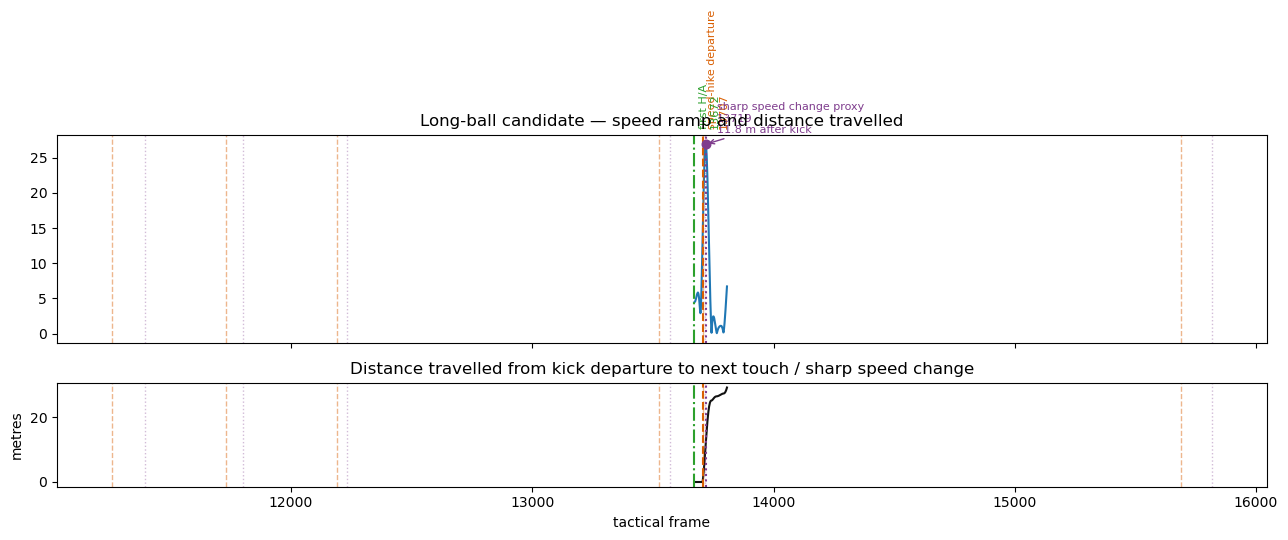

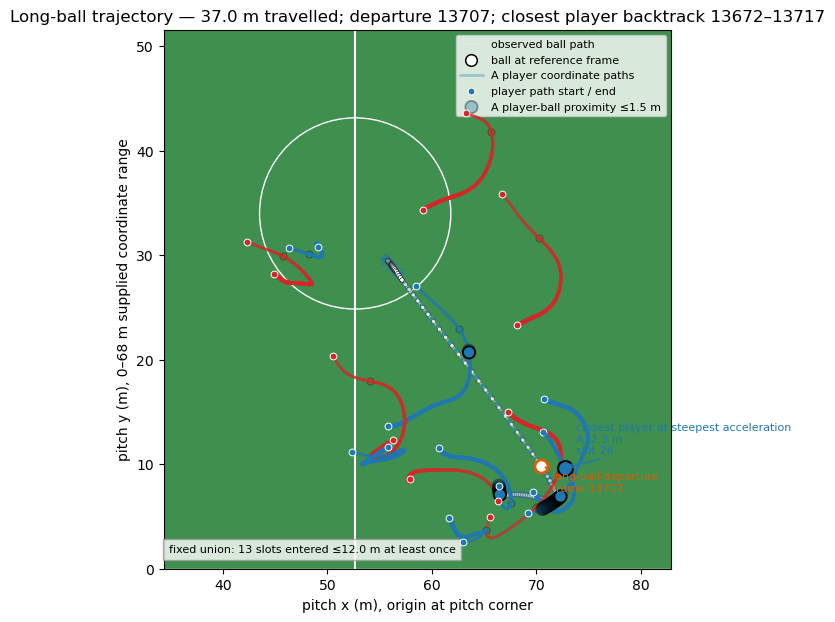

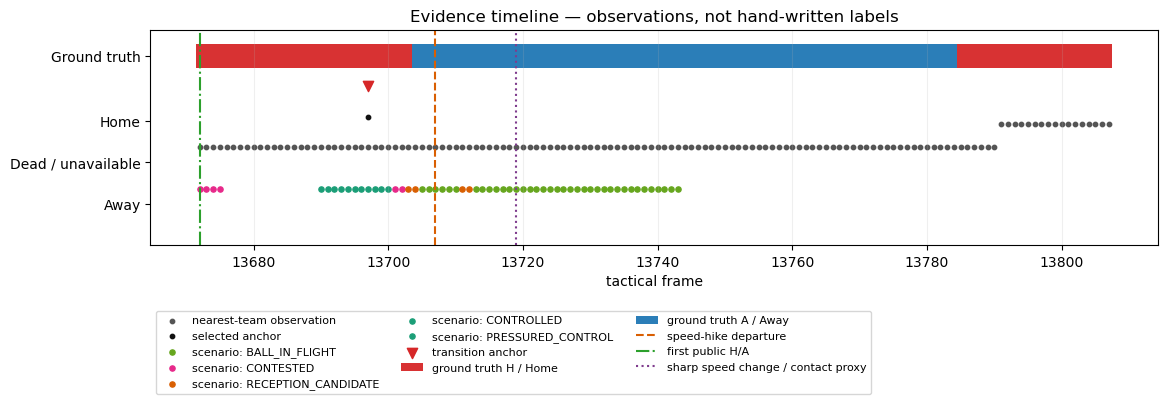

In [12]:
# Long-ball study: scan the public five-minute interval for a low-speed-to-high-speed trajectory.
scan = features.copy()
scan['speed_mps'] = np.hypot(scan.ball_x.diff() * PITCH_LENGTH_M, scan.ball_y.diff() * PITCH_WIDTH_M) * 25
scan['accel_mps2'] = scan.speed_mps.diff() * 25
scan['step_distance_m'] = np.hypot(scan.ball_x.diff() * PITCH_LENGTH_M, scan.ball_y.diff() * PITCH_WIDTH_M)
candidate = scan.loc[scan.accel_mps2.ge(20) & scan.speed_mps.ge(15)].copy()
# A kick is the departure impulse: the strongest positive dv/dt after a
# preceding low-speed/reset point.  The local minimum is therefore
# context, not the kick frame itself.  Keep separated peaks so one
# prolonged acceleration ramp cannot create duplicate kick rows.
kick_distance_table = pd.DataFrame()
if not candidate.empty:
    candidate['is_accel_peak'] = candidate.accel_mps2.ge(candidate.accel_mps2.rolling(5, center=True, min_periods=1).max())
    peak_candidates = candidate.loc[candidate.is_accel_peak].sort_values('accel_mps2', ascending=False)
    selected_kicks = []
    for _, row in peak_candidates.iterrows():
        frame = int(row.frame)
        if all(abs(frame - prior) >= 5 for prior in selected_kicks): selected_kicks.append(frame)
    kick_frames = sorted(selected_kicks)
    scan['jerk_proxy_mps3'] = scan.accel_mps2.diff() * 25
    kick_rows = []
    for kick_i, kick_frame_i in enumerate(kick_frames, start=1):
        kick_row_i = scan.loc[scan.frame.eq(kick_frame_i)].iloc[0]
        prior = scan.loc[scan.frame.between(kick_frame_i - 15, kick_frame_i - 1)]
        low_prior = prior.loc[prior.speed_mps.le(5)]
        pre_frame = int(low_prior.iloc[-1].frame) if not low_prior.empty else (int(prior.iloc[-1].frame) if not prior.empty else None)
        next_kick = kick_frames[kick_i] if kick_i < len(kick_frames) else PUBLIC_END
        after = scan.loc[scan.frame.between(kick_frame_i + 3, next_kick - 1)].copy()
        after['speed_local_min'] = after.speed_mps.le(after.speed_mps.rolling(9, center=True, min_periods=3).min().add(0.15))
        after['near_player_control'] = after.get('closest_distance_m', pd.Series(np.inf, index=after.index)).le(2.5)
        touch_i = after.loc[after.speed_mps.le(5) & after.speed_local_min & after.near_player_control]
        sharp_i = after.loc[after.jerk_proxy_mps3.abs().ge(120)]
        event_candidates_i = []
        if not touch_i.empty: event_candidates_i.append((int(touch_i.iloc[0].frame), 'controlled touch / reception proxy'))
        if not sharp_i.empty: event_candidates_i.append((int(sharp_i.iloc[0].frame), 'sharp speed change / possible touch or miscontrol'))
        if kick_i < len(kick_frames): event_candidates_i.append((next_kick, 'next separated acceleration / possible second kick'))
        event_frame_i, event_type_i = min(event_candidates_i, key=lambda item: item[0]) if event_candidates_i else (int(after.iloc[-1].frame) if not after.empty else kick_frame_i, 'no follow-up event detected')
        seg_i = scan.loc[scan.frame.between(kick_frame_i, event_frame_i)]
        out_i = seg_i.get('ball_out_of_bounds', pd.Series(False, index=seg_i.index)).fillna(False).astype(bool)
        kick_rows.append({'kick_index': kick_i, 'pre_kick_reset_frame': pre_frame, 'kick_departure_frame': kick_frame_i, 'departure_speed_mps': float(kick_row_i.speed_mps), 'departure_acceleration_mps2': float(kick_row_i.accel_mps2), 'end_frame': event_frame_i, 'end_event': event_type_i, 'distance_kick_to_event_m': float(seg_i.step_distance_m.fillna(0).sum()), 'ball_in_play_through_event': not bool(out_i.any())})
    kick_distance_table = pd.DataFrame(kick_rows)
if candidate.empty:
    print('No strict long-ball signature found in the public five-minute interval.')
else:
    dep = candidate.loc[candidate.accel_mps2.idxmax()]; dep_frame = int(dep.frame)
    representative_kick = kick_distance_table.iloc[(kick_distance_table.kick_departure_frame - dep_frame).abs().argmin()]
    dep_row = features.loc[features.frame.eq(dep_frame)].iloc[0]
    player_distances = []
    for slot, team in team_by_slot.items():
        px, py = dep_row.get(f'{slot}_x'), dep_row.get(f'{slot}_y')
        if pd.notna(px) and pd.notna(py) and pd.notna(dep_row.ball_x) and pd.notna(dep_row.ball_y):
            d = float(np.hypot((px - dep_row.ball_x) * PITCH_LENGTH_M, (py - dep_row.ball_y) * PITCH_WIDTH_M))
            player_distances.append((d, int(slot), team, float(px), float(py)))
    closest_distance, closest_slot, closest_team, closest_x, closest_y = min(player_distances, key=lambda item: item[0])
    backtrack_start, backtrack_end = max(PUBLIC_START, dep_frame - 35), min(PUBLIC_END, dep_frame + 10)
    player_path = features.loc[features.frame.between(backtrack_start, backtrack_end), ['frame', f'{closest_slot}_x', f'{closest_slot}_y']].dropna()
    start, end = max(PUBLIC_START, dep_frame - 35), min(PUBLIC_END, dep_frame + 100)
    local = scan.loc[scan.frame.between(start, end)].copy()
    # After the steepest acceleration, locate the first sharp, non-smooth
    # change in the speed curve.  This is a contact/reception proxy: it
    # can indicate a header, touch, or tracking change, but is not a
    # definitive event label without event-level touch data.
    local['jerk_proxy_mps3'] = local.accel_mps2.diff() * 25
    peak_frame = int(local.loc[local.speed_mps.idxmax(), 'frame'])
    post_peak = local.loc[local.frame.ge(peak_frame)].copy()
    post_peak['speed_local_min'] = post_peak.speed_mps <= post_peak.speed_mps.rolling(9, center=True, min_periods=3).min().add(0.15)
    post_peak['near_player_control'] = post_peak.get('closest_distance_m', pd.Series(np.inf, index=post_peak.index)).le(2.5)
    touch = post_peak.loc[(post_peak.speed_mps.le(5)) & post_peak.speed_local_min & post_peak.near_player_control & post_peak.frame.gt(dep_frame + 2)]
    sharp = post_peak.loc[post_peak.frame.gt(dep_frame + 2) & post_peak.jerk_proxy_mps3.abs().ge(120)]
    second_kick = post_peak.loc[post_peak.frame.gt(dep_frame + 2) & post_peak.accel_mps2.ge(20) & post_peak.jerk_proxy_mps3.ge(120)]
    event_rows = []
    if not touch.empty: event_rows.append((int(touch.iloc[0].frame), 'controlled touch proxy', touch.iloc[0]))
    if not sharp.empty: event_rows.append((int(sharp.iloc[0].frame), 'sharp speed change proxy', sharp.iloc[0]))
    if not second_kick.empty: event_rows.append((int(second_kick.iloc[0].frame), 'second acceleration / possible second kick or miscontrol', second_kick.iloc[0]))
    if event_rows:
        contact_frame, contact_event, contact_row = min(event_rows, key=lambda item: item[0])
    else:
        contact_row = post_peak.iloc[-1]; contact_frame = int(contact_row.frame); contact_event = 'no follow-up event detected in window'
    contact_speed = float(contact_row.speed_mps) if pd.notna(contact_row.speed_mps) else np.nan
    contact_accel = float(contact_row.accel_mps2) if pd.notna(contact_row.accel_mps2) else np.nan
    post_kick_segment = local.loc[local.frame.between(dep_frame, contact_frame)]
    post_kick_distance = float(post_kick_segment.step_distance_m.fillna(0).sum())
    local['distance_from_kick_m'] = local.step_distance_m.where(local.frame.ge(dep_frame), 0).fillna(0).cumsum()
    out_flag = post_kick_segment.get('ball_out_of_bounds', pd.Series(False, index=post_kick_segment.index)).fillna(False).astype(bool)
    ball_in_play_through_contact = not bool(out_flag.any())
    end_frame = contact_frame
    observed = local.dropna(subset=['ball_x', 'ball_y'])
    travelled = float(observed.step_distance_m.sum())
    displacement = float(np.hypot((observed.ball_x.iloc[-1] - observed.ball_x.iloc[0]) * PITCH_LENGTH_M, (observed.ball_y.iloc[-1] - observed.ball_y.iloc[0]) * PITCH_WIDTH_M))
    gt_local = gt_by_frame.reindex(range(start, end + 1)).dropna(); gt_changes = gt_local.loc[gt_local.ne(gt_local.shift())]
    first_ha = gt_local.loc[gt_local.isin(['H', 'A'])]; first_ha_frame = int(first_ha.index[0]) if not first_ha.empty else None
    display(kick_distance_table)
    display(pd.DataFrame([{'departure_frame': dep_frame, 'departure_speed_mps': float(dep.speed_mps), 'departure_acceleration_mps2': float(dep.accel_mps2), 'peak_speed_mps': float(local.speed_mps.max()), 'travelled_distance_m': travelled, 'straight_displacement_m': displacement, 'event_frame': contact_frame, 'event_type': contact_event, 'event_speed_mps': contact_speed, 'event_acceleration_mps2': contact_accel, 'distance_kick_to_event_m': post_kick_distance, 'ball_in_play_through_event': ball_in_play_through_contact, 'first_public_H_or_A': first_ha_frame, 'closest_player_slot_at_departure': closest_slot, 'closest_player_team_at_departure': closest_team, 'closest_player_distance_m_at_departure': closest_distance, 'ground_truth_changes': ' → '.join(f'{int(i)}:{v}' for i, v in gt_changes.items())}]))
    fig, (speed_ax, dist_ax) = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
    local.plot(x='frame', y='speed_mps', ax=speed_ax, color='#1f77b4', legend=False, title='Long-ball candidate — speed ramp and distance travelled')
    local.plot(x='frame', y='distance_from_kick_m', ax=dist_ax, color='#111111', legend=False, title='Distance travelled from kick departure to next touch / sharp speed change')
    for axis in (speed_ax, dist_ax):
        axis.axvline(dep_frame, color='#d95f02', ls='--'); axis.axvline(end_frame, color='#7f3c8d', ls=':')
        if first_ha_frame is not None: axis.axvline(first_ha_frame, color='#2ca02c', ls='-.')
        for _, kick_event in kick_distance_table.iterrows():
            axis.axvline(kick_event.kick_departure_frame, color='#d95f02', ls='--', alpha=.45, linewidth=1)
            axis.axvline(kick_event.end_frame, color='#7f3c8d', ls=':', alpha=.35, linewidth=1)
    speed_ax.scatter([contact_frame], [contact_speed], s=38, color='#7f3c8d', zorder=5)
    speed_ax.annotate(f'speed-hike departure\n{dep_frame}', (dep_frame, 1), xycoords=('data', 'axes fraction'), xytext=(3, 4), textcoords='offset points', rotation=90, va='bottom', fontsize=8, color='#d95f02')
    speed_ax.annotate(f'{contact_event}\n{contact_frame}\n{post_kick_distance:.1f} m after kick', (contact_frame, contact_speed), xytext=(8, 8), textcoords='offset points', fontsize=8, color='#7f3c8d', arrowprops={'arrowstyle':'->', 'color':'#7f3c8d'})
    if first_ha_frame is not None: speed_ax.annotate(f'first H/A\n{first_ha_frame}', (first_ha_frame, 1), xycoords=('data', 'axes fraction'), xytext=(3, 4), textcoords='offset points', rotation=90, va='bottom', fontsize=8, color='#2ca02c')
    dist_ax.set_xlabel('tactical frame'); dist_ax.set_ylabel('metres'); plt.tight_layout(); plt.show()
    fig, ax = plt.subplots(figsize=(11, 7))
    plot_trajectory_window(features, start, end, team_by_slot=team_by_slot, reference_frame=dep_frame, nearby_radius_m=12.0, nearby_count=None, zoom_to_involved=True, show_all_reference_players=False, touch_radius_m=1.5, ax=ax)
    if not player_path.empty:
        path_color = '#d62728' if closest_team == 'H' else '#1f77b4'
        ax.plot(player_path[f'{closest_slot}_x'] * PITCH_LENGTH_M, player_path[f'{closest_slot}_y'] * PITCH_WIDTH_M, color=path_color, linewidth=3.0, alpha=0.9, zorder=8)
        ax.scatter([closest_x * PITCH_LENGTH_M], [closest_y * PITCH_WIDTH_M], s=115, facecolor=path_color, edgecolor='black', linewidth=1.5, zorder=10)
        ax.annotate(f'closest player at steepest acceleration\n{closest_team}, {closest_distance:.1f} m\nslot {closest_slot}', (closest_x * PITCH_LENGTH_M, closest_y * PITCH_WIDTH_M), xytext=(8, 10), textcoords='offset points', fontsize=8, color=path_color, arrowprops={'arrowstyle':'->', 'color':path_color}, zorder=11)
    ax.scatter([dep_row.ball_x * PITCH_LENGTH_M], [dep_row.ball_y * PITCH_WIDTH_M], s=90, facecolor='white', edgecolor='#d95f02', linewidth=2, zorder=11)
    ax.annotate(f'long-ball departure\nframe {dep_frame}', (dep_row.ball_x * PITCH_LENGTH_M, dep_row.ball_y * PITCH_WIDTH_M), xytext=(8, -18), textcoords='offset points', fontsize=8, color='#d95f02', arrowprops={'arrowstyle':'->', 'color':'#d95f02'}, zorder=11)
    ax.set_title(f'Long-ball trajectory — {travelled:.1f} m travelled; departure {dep_frame}; closest player backtrack {backtrack_start}–{backtrack_end}')
    plt.show()
    fig, ax = plt.subplots(figsize=(13, 2.8))
    plot_timeline_window(features, start, end, ground_truth=gt_by_frame, ax=ax)
    ax.axvline(dep_frame, color='#d95f02', ls='--', label='speed-hike departure')
    if first_ha_frame is not None: ax.axvline(first_ha_frame, color='#2ca02c', ls='-.', label='first public H/A')
    ax.axvline(end_frame, color='#7f3c8d', ls=':', label='sharp speed change / contact proxy')
    ax.legend(loc='upper left', bbox_to_anchor=(0, -0.28), ncol=3, fontsize=8); plt.show()

In [13]:
# H↔A transition audit: expose engineered predictors around every public label switch.
gt_public = gt_by_frame.reindex(features.frame).dropna()
ha_switches = gt_public.loc[gt_public.ne(gt_public.shift()) & gt_public.isin(['H', 'A'])]
ha_switches = ha_switches.loc[ha_switches.shift(1).isin(['H', 'A'])]
feature_tokens = ('distance', 'density', 'margin', 'speed', 'acceleration', 'pressure', 'control', 'anchor', 'scenario', 'ball')
predictor_cols = [c for c in features.columns if any(token in c.lower() for token in feature_tokens) and c not in {'frame'}]
predictor_cols = [c for c in predictor_cols if not c.endswith(('_x', '_y'))]
transition_rows = []
for transition_frame, new_label in ha_switches.items():
    before = gt_by_frame.get(int(transition_frame) - 1)
    row = {'transition_frame': int(transition_frame), 'from_label': before, 'to_label': new_label}
    match = features.loc[features.frame.eq(int(transition_frame))]
    if not match.empty:
        row.update(match.iloc[0][predictor_cols].to_dict())
    transition_rows.append(row)
transition_feature_audit = pd.DataFrame(transition_rows)
print(f'H↔A transitions in public window: {len(transition_feature_audit)}')
display(transition_feature_audit)
display(pd.DataFrame({'predictor_feature': predictor_cols, 'available': [features[c].notna().sum() for c in predictor_cols]}))

H↔A transitions in public window: 16


,transition_frame,from_label,to_label,ball_z,smart_ball_in_final_third,smart_ball_in_final_third_team,smart_ball_in_the_box,smart_ball_in_the_box_team,smart_long_ball,smart_long_ball_team,...,selected_anchor_team,selected_anchor_source,selected_anchor_confidence,has_selected_anchor,scenario_episode_id,scenario_episode_length_frames,scenario_episode_start,scenario_episode_end,scenario_episode_position_frames,scenario_episode_fraction
0,11351,A,H,NaN,True,A,True,A,True,A,...,NaN,NO_ANCHOR,0.00,False,27,5,False,False,1,0.250000
1,11553,H,A,NaN,True,A,True,A,False,None,...,NaN,NO_ANCHOR,0.00,False,43,13,False,False,11,0.916667
2,11624,A,H,NaN,True,A,True,A,False,None,...,H,pressure_anchor_team,0.95,True,57,75,False,False,10,0.135135
3,12665,H,A,NaN,True,A,False,None,False,None,...,NaN,NO_ANCHOR,0.00,False,175,34,False,False,15,0.454545
4,12989,D,H,NaN,False,None,False,None,False,None,...,NaN,NO_ANCHOR,0.00,False,202,17,False,False,9,0.562500
5,13704,H,A,NaN,False,None,False,None,False,None,...,NaN,NO_ANCHOR,0.00,False,297,2,False,True,1,1.000000
6,13785,A,H,NaN,True,H,False,None,False,None,...,NaN,NO_ANCHOR,0.00,False,301,47,False,False,41,0.891304
7,14846,H,A,NaN,False,None,False,None,False,None,...,NaN,NO_ANCHOR,0.00,False,438,9,True,False,0,0.000000
8,15346,A,H,NaN,False,None,False,None,False,None,...,NaN,NO_ANCHOR,0.00,False,486,66,False,False,55,0.846154
9,15365,H,A,NaN,False,None,False,None,False,None,...,NaN,NO_ANCHOR,0.00,False,489,1,True,True,0,0.000000


,predictor_feature,available
0,ball_z,0
1,smart_ball_in_final_third,7500
2,smart_ball_in_final_third_team,3748
3,smart_ball_in_the_box,7500
4,smart_ball_in_the_box_team,1380
...,...,...
156,scenario_episode_length_frames,7500
157,scenario_episode_start,7500
158,scenario_episode_end,7500
159,scenario_episode_position_frames,7500


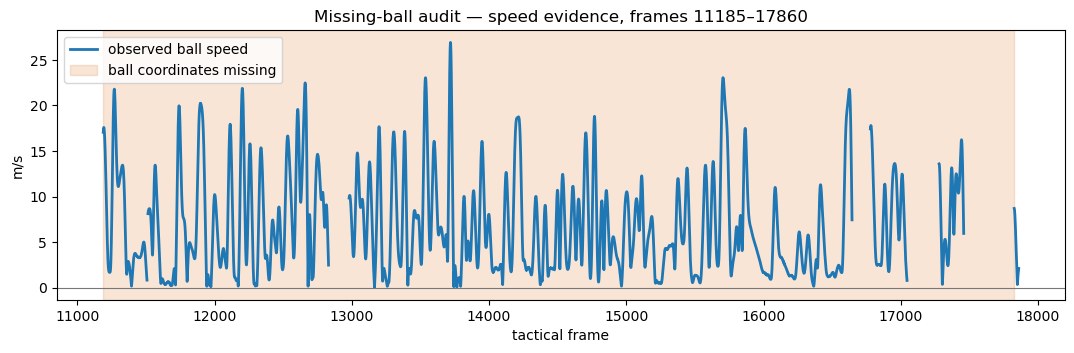

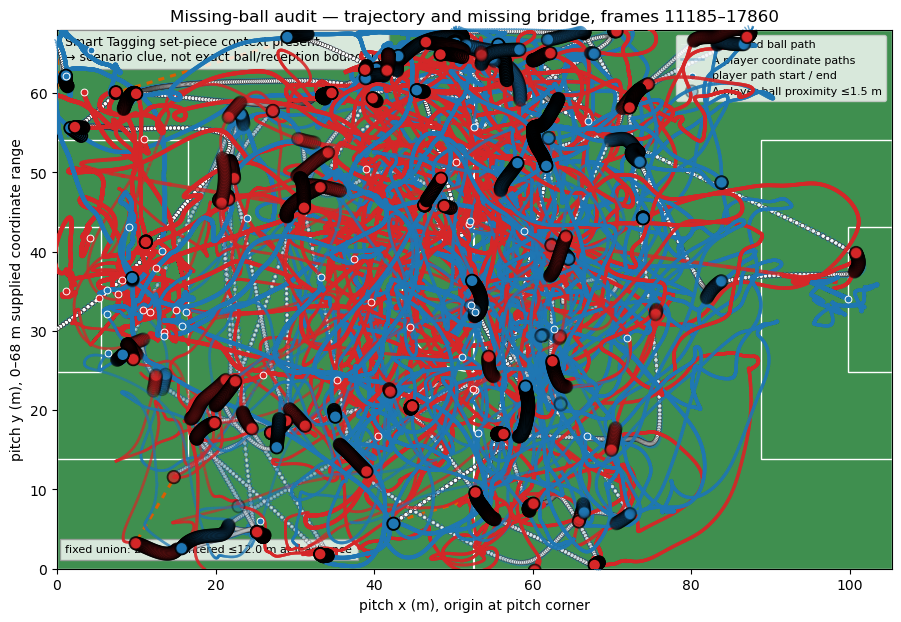

Contested-ball signal frames: 68 | peak speed: 19.44 m/s | max density: 1


/var/folders/hx/0wt7j0md7ld6cq4m77bhf6w80000gn/T/vscode-agent-codex-sandbox-ppwJ0N/ipykernel_71045/1149668809.py:49: RuntimeWarning: All-NaN slice encountered
  transition_window['best_zone_speed_match_error_mps'] = np.nanmin(masked_errors, axis=1)


,frame,ball_speed_derived_mps,ball_speed_drop_mps,ball_acceleration_mps2,ball_direction_change_rad,direction_target_team,direction_target_slot,direction_target_angle_error_rad,direction_target_distance_m,direction_target_found,...,gegenpress_candidate,gegenpress_score,possession_zone_player_count,best_zone_speed_match_error_mps,high_speed_no_control_signal,sharp_deceleration_reception_veto,sharp_acceleration_pass_veto,deflection_direction_change_veto,first_time_pass_after_long_ball_risk,scenario_context
11331,11331,13.352283,0.062577,-1.564431,0.000267,A,45.0,0.155538,3.248508,True,...,False,0.0,0,NaN,True,False,False,False,False,BALL_IN_FLIGHT
11332,11332,13.281334,0.070949,-1.773715,0.001380,A,45.0,0.174117,3.038233,True,...,False,0.0,0,NaN,True,False,False,False,False,BALL_IN_FLIGHT
11333,11333,13.164592,0.116742,-2.918553,0.000571,A,45.0,0.199095,2.831286,True,...,False,0.0,0,NaN,True,False,False,False,False,BALL_IN_FLIGHT
11334,11334,13.008157,0.156435,-3.910875,0.000691,A,45.0,0.227974,2.628550,True,...,False,0.0,0,NaN,True,False,False,False,False,BALL_IN_FLIGHT
11335,11335,12.851713,0.156444,-3.911090,0.000709,A,45.0,0.263150,2.430874,True,...,False,0.0,0,NaN,True,False,False,False,False,BALL_IN_FLIGHT
11336,11336,12.603758,0.247955,-6.198883,0.003375,A,45.0,0.311158,2.243249,True,...,False,0.0,0,NaN,True,False,False,False,False,BALL_IN_FLIGHT
11337,11337,12.353422,0.250336,-6.258392,0.001123,A,45.0,0.363883,2.067978,True,...,False,0.0,0,NaN,True,False,False,False,False,BALL_IN_FLIGHT
11338,11338,12.042888,0.310534,-7.763362,0.003289,H,3.0,0.435946,3.611909,True,...,False,0.0,1,4.784565,True,False,False,False,False,BALL_IN_FLIGHT
11339,11339,11.707191,0.335696,-8.392406,0.000314,H,3.0,0.472821,3.468179,True,...,False,0.0,1,4.560277,True,False,False,False,False,BALL_IN_FLIGHT
11340,11340,11.311403,0.395788,-9.894705,0.004441,H,3.0,0.516614,3.343369,True,...,False,0.0,1,4.241435,True,False,False,False,False,BALL_IN_FLIGHT


,transition_number,ground_truth_transition_frame,nearest_engineered_anchor_frame,anchor_team,anchor_source,anchor_confidence,scenario_at_transition,ball_missing_at_transition
0,2,11351,11351,NaN,NO_ANCHOR,0.0,BALL_IN_FLIGHT,False


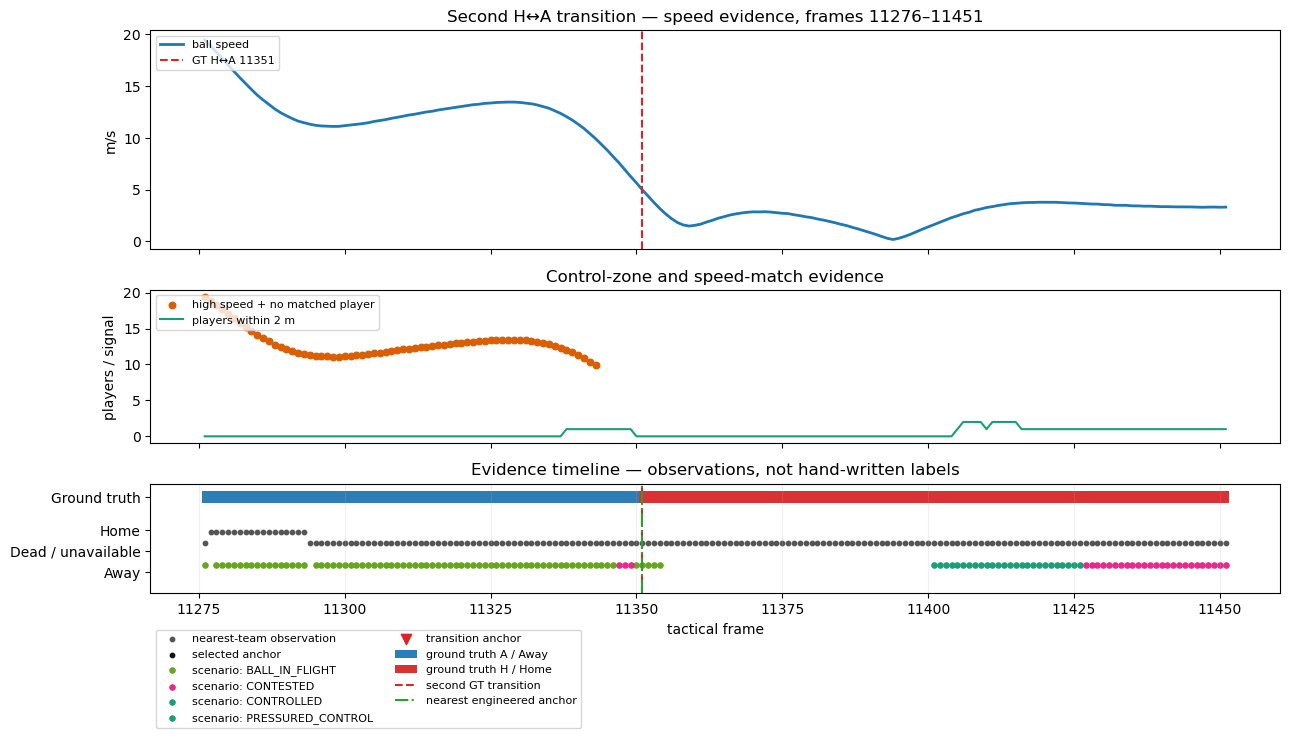

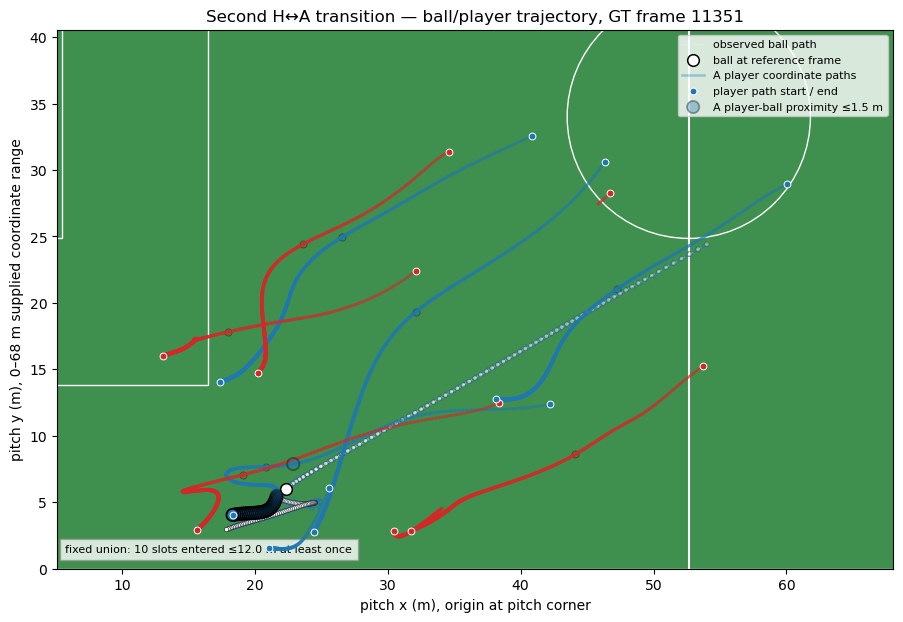

In [14]:
# Missing-ball evidence and the second H↔A transition in the public window.
public = features.loc[features.frame.between(PUBLIC_START, PUBLIC_END)].copy()
missing_mask = public.ball_x.isna() | public.ball_y.isna()
if missing_mask.any():
    missing_frames = public.loc[missing_mask, 'frame']
    gap_start, gap_end = int(missing_frames.iloc[0]), int(missing_frames.iloc[-1])
    start, end = max(PUBLIC_START, gap_start - 35), min(PUBLIC_END, gap_end + 35)
    audit = public.loc[public.frame.between(start, end)].copy()
    fig, ax = plt.subplots(figsize=(13, 3.5))
    ax.plot(audit.frame, audit.ball_speed_derived_mps, color='#1f77b4', linewidth=2, label='observed ball speed')
    local_missing = audit.ball_x.isna() | audit.ball_y.isna()
    ax.axvspan(int(audit.loc[local_missing, 'frame'].min()), int(audit.loc[local_missing, 'frame'].max()), color='#d95f02', alpha=0.16, label='ball coordinates missing')
    ax.axhline(0, color='#777', linewidth=0.8); ax.set_title(f'Missing-ball audit — speed evidence, frames {start}–{end}'); ax.set_xlabel('tactical frame'); ax.set_ylabel('m/s'); ax.legend(loc='upper left'); plt.show()
    fig, ax = plt.subplots(figsize=(11, 7))
    plot_trajectory_window(public, start, end, team_by_slot=team_by_slot, reference_frame=gap_start, nearby_radius_m=12.0, nearby_count=None, zoom_to_involved=True, show_all_reference_players=False, touch_radius_m=1.5, ax=ax)
    ax.set_title(f'Missing-ball audit — trajectory and missing bridge, frames {start}–{end}'); plt.show()
else:
    print('No missing-ball frames in the public five-minute interval.')
ha_changes = gt_by_frame.reindex(range(PUBLIC_START, PUBLIC_END + 1)).dropna()
ha_changes = ha_changes.loc[ha_changes.ne(ha_changes.shift()) & ha_changes.isin(['H', 'A'])]
second_transition_frame = int(ha_changes.index[1]) if len(ha_changes) >= 2 else None
if second_transition_frame is None:
    print('Fewer than two H↔A transitions in the public five-minute interval.')
else:
    transition_start, transition_end = max(PUBLIC_START, second_transition_frame - 75), min(PUBLIC_END, second_transition_frame + 100)
    transition_window = public.loc[public.frame.between(transition_start, transition_end)].copy()
    # Contested-ball diagnostic: a fast ball with no plausible player control.
    # A possession-zone player must be within 2 m and moving at a comparable
    # speed; otherwise the frame is evidence of flight/contest, not control.
    possession_radius_m = 2.0
    speed_match_tolerance_mps = 3.0
    slot_distances = []
    slot_speed_errors = []
    for slot in sorted(team_by_slot):
        x_col, y_col = f'{slot}_x', f'{slot}_y'
        if x_col not in transition_window or y_col not in transition_window: continue
        px = pd.to_numeric(transition_window[x_col], errors='coerce')
        py = pd.to_numeric(transition_window[y_col], errors='coerce')
        distance = np.hypot((px - transition_window.ball_x) * PITCH_LENGTH_M, (py - transition_window.ball_y) * PITCH_WIDTH_M)
        player_speed = np.hypot(px.diff() * PITCH_LENGTH_M, py.diff() * PITCH_WIDTH_M) * 25
        slot_distances.append(distance.to_numpy(float))
        slot_speed_errors.append((player_speed - transition_window.ball_speed_derived_mps).abs().to_numpy(float))
    if slot_distances:
        distance_matrix = np.column_stack(slot_distances)
        speed_error_matrix = np.column_stack(slot_speed_errors)
        in_zone = np.isfinite(distance_matrix) & (distance_matrix <= possession_radius_m)
        transition_window['possession_zone_player_count'] = in_zone.sum(axis=1)
        masked_errors = np.where(in_zone, speed_error_matrix, np.nan)
        transition_window['best_zone_speed_match_error_mps'] = np.nanmin(masked_errors, axis=1)
    else:
        transition_window['possession_zone_player_count'] = 0
        transition_window['best_zone_speed_match_error_mps'] = np.nan
    transition_window['high_speed_no_control_signal'] = (
        transition_window.ball_speed_derived_mps.ge(8.0)
        & ((transition_window.possession_zone_player_count.eq(0))
           | transition_window.best_zone_speed_match_error_mps.gt(speed_match_tolerance_mps))
    )
    signal_rows = transition_window.loc[transition_window.high_speed_no_control_signal]
    print('Contested-ball signal frames:', int(len(signal_rows)), '| peak speed:', round(float(transition_window.ball_speed_derived_mps.max()), 2), 'm/s', '| max density:', int(transition_window.candidate_opponent_density_5m.max()))
    display(transition_window.loc[transition_window.frame.between(second_transition_frame - 20, second_transition_frame + 20), ['frame','ball_speed_derived_mps','ball_speed_drop_mps','ball_acceleration_mps2','ball_direction_change_rad','direction_target_team','direction_target_slot','direction_target_angle_error_rad','direction_target_distance_m','direction_target_found','forecast_touch_team','forecast_touch_frame','forecast_touch_offset_frames','forecast_post_touch_anchor_frames','anchor_forecast_confidence','anchor_forecast_confirmed','closest_distance_m','candidate_opponent_density_5m','candidate_pressure_m','opponent_closing_speed_mps','opponent_directional_coverage_score','candidate_teammate_support_10m','candidate_pass_options_15m','short_option_blocked','gegenpress_candidate','gegenpress_score','possession_zone_player_count','best_zone_speed_match_error_mps','high_speed_no_control_signal','sharp_deceleration_reception_veto','sharp_acceleration_pass_veto','deflection_direction_change_veto','first_time_pass_after_long_ball_risk','scenario_context']])
    nearest_anchor = features.loc[(features.frame - second_transition_frame).abs().idxmin()]
    display(pd.DataFrame([{'transition_number': 2, 'ground_truth_transition_frame': second_transition_frame, 'nearest_engineered_anchor_frame': int(nearest_anchor.frame), 'anchor_team': nearest_anchor.selected_anchor_team, 'anchor_source': nearest_anchor.selected_anchor_source, 'anchor_confidence': nearest_anchor.selected_anchor_confidence, 'scenario_at_transition': nearest_anchor.scenario_context, 'ball_missing_at_transition': bool(pd.isna(nearest_anchor.ball_x) or pd.isna(nearest_anchor.ball_y))}]))
    fig, (speed_ax, evidence_ax, timeline_ax) = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={'height_ratios':[2, 1.4, 1]})
    speed_ax.plot(transition_window.frame, transition_window.ball_speed_derived_mps, color='#1f77b4', linewidth=2, label='ball speed')
    missing = transition_window.ball_x.isna() | transition_window.ball_y.isna()
    if missing.any(): speed_ax.axvspan(int(transition_window.loc[missing, 'frame'].min()), int(transition_window.loc[missing, 'frame'].max()), color='#d95f02', alpha=0.16, label='ball missing')
    speed_ax.axvline(second_transition_frame, color='#d62728', linestyle='--', label=f'GT H↔A {second_transition_frame}'); speed_ax.set_title(f'Second H↔A transition — speed evidence, frames {transition_start}–{transition_end}'); speed_ax.set_ylabel('m/s'); speed_ax.legend(loc='upper left', fontsize=8)
    if signal_rows.empty:
        evidence_ax.text(0.5, 0.5, 'No high-speed/no-control signal in this window', transform=evidence_ax.transAxes, ha='center', va='center')
    else:
        evidence_ax.scatter(signal_rows.frame, signal_rows.ball_speed_derived_mps, color='#d95f02', s=22, label='high speed + no matched player')
    decel_rows = transition_window.loc[transition_window.get('sharp_deceleration_reception_veto', False)]
    accel_rows = transition_window.loc[transition_window.get('sharp_acceleration_pass_veto', False)]
    turn_rows = transition_window.loc[transition_window.get('deflection_direction_change_veto', False)]
    if not decel_rows.empty: evidence_ax.scatter(decel_rows.frame, decel_rows.ball_speed_derived_mps, color='#7f3c8d', marker='o', s=28, label='sharp deceleration / reception')
    if not accel_rows.empty: evidence_ax.scatter(accel_rows.frame, accel_rows.ball_speed_derived_mps, color='#e66101', marker='^', s=30, label='sharp acceleration / pass')
    if not turn_rows.empty: evidence_ax.scatter(turn_rows.frame, turn_rows.ball_speed_derived_mps, color='#d62728', marker='x', s=34, label='direction change / deflection risk')
    evidence_ax.plot(transition_window.frame, transition_window.possession_zone_player_count, color='#1b9e77', label='players within 2 m')
    evidence_ax.set_ylabel('players / signal'); evidence_ax.set_title('Control-zone and speed-match evidence'); evidence_ax.legend(loc='upper left', fontsize=8)
    plot_timeline_window(public, transition_start, transition_end, ground_truth=gt_by_frame, ax=timeline_ax)
    timeline_ax.axvline(second_transition_frame, color='#d62728', linestyle='--', label='second GT transition'); timeline_ax.axvline(int(nearest_anchor.frame), color='#2ca02c', linestyle='-.', label='nearest engineered anchor'); timeline_ax.legend(loc='upper left', bbox_to_anchor=(0, -0.28), ncol=2, fontsize=8); plt.tight_layout(); plt.show()
    fig, ax = plt.subplots(figsize=(11, 7))
    plot_trajectory_window(public, transition_start, transition_end, team_by_slot=team_by_slot, reference_frame=second_transition_frame, nearby_radius_m=12.0, nearby_count=None, zoom_to_involved=True, show_all_reference_players=False, touch_radius_m=1.5, ax=ax)
    ax.set_title(f'Second H↔A transition — ball/player trajectory, GT frame {second_transition_frame}'); plt.show()

In [15]:
## Public D-to-H/A timing by restart context
# Audit only: public labels validate timing; they do not generate pipeline labels.
public_audit = features.loc[features.frame.between(PUBLIC_START, PUBLIC_END)].copy()
public_audit['gt_label'] = gt_by_frame.reindex(public_audit.frame).to_numpy()
public_audit['gt_segment_id'] = public_audit.gt_label.ne(public_audit.gt_label.shift()).cumsum()
segments = public_audit.groupby('gt_segment_id', as_index=False).agg(gt_start_frame=('frame','min'), gt_end_frame=('frame','max'), gt_label=('gt_label','first'), gt_frames=('frame','size'))
d_segments = segments.loc[segments.gt_label.eq('D')]
restart_rows = []
for tag in smart_tags:
    if str(tag.get('code', '')).upper() != 'SET PIECES': continue
    tag_type = str((tag.get('tags', {}) or {}).get('Type', 'UNKNOWN'))
    tag_start = int(tag.get('start_frame', tag.get('start', -1)))
    tag_end = int(tag.get('end_frame', tag.get('end', tag_start)))
    if tag_end < PUBLIC_START or tag_start > PUBLIC_END: continue
    search = gt_by_frame.reindex(range(max(PUBLIC_START, tag_start), PUBLIC_END + 1))
    ha = search.loc[search.isin(['H', 'A'])]
    first_ha = int(ha.index[0]) if len(ha) else np.nan
    overlap = d_segments.loc[(d_segments.gt_end_frame >= tag_start) & (d_segments.gt_start_frame <= tag_end)]
    d_start = int(overlap.gt_start_frame.iloc[0]) if len(overlap) else np.nan
    d_end = int(overlap.gt_end_frame.iloc[0]) if len(overlap) else np.nan
    restart_rows.append({'restart_type':tag_type, 'tag_start_frame':tag_start, 'tag_end_frame':tag_end, 'gt_label_at_tag_start':gt_by_frame.get(tag_start), 'gt_d_start_frame':d_start, 'gt_d_end_frame':d_end, 'gt_d_duration_s':(d_end-d_start+1)/25 if pd.notna(d_start) else np.nan, 'first_gt_ha_frame_after_tag':first_ha, 'restart_to_first_gt_ha_s':(first_ha-tag_start)/25 if pd.notna(first_ha) else np.nan})
restart_delay_audit = pd.DataFrame(restart_rows)
display(restart_delay_audit)
display(restart_delay_audit.groupby('restart_type', dropna=False).agg(events=('tag_start_frame','size'), median_d_duration_s=('gt_d_duration_s','median'), median_restart_to_gt_ha_s=('restart_to_first_gt_ha_s','median'), min_restart_to_gt_ha_s=('restart_to_first_gt_ha_s','min'), max_restart_to_gt_ha_s=('restart_to_first_gt_ha_s','max')).reset_index())


,restart_type,tag_start_frame,tag_end_frame,gt_label_at_tag_start,gt_d_start_frame,gt_d_end_frame,gt_d_duration_s,first_gt_ha_frame_after_tag,restart_to_first_gt_ha_s
0,Kick Off (Start),11097,11222,X,NaN,NaN,NaN,11185,3.52
1,Goal Kick,18320,19195,D,18027.0,18388.0,14.48,18389,2.76
2,Free Kick,17533,18408,D,17380.0,17837.0,18.32,17838,12.20


,restart_type,events,median_d_duration_s,median_restart_to_gt_ha_s,min_restart_to_gt_ha_s,max_restart_to_gt_ha_s
0,Free Kick,1,18.32,12.20,12.20,12.20
1,Goal Kick,1,14.48,2.76,2.76,2.76
2,Kick Off (Start),1,NaN,3.52,3.52,3.52


## Findings carried into the pipeline

- Comfortable control: small ball-to-player distance; meaningful team margin; no nearby opponent challenge.
- Smart Tagging: scenario clue; check selector; not exact possession boundary.
- D: restart tag, out-of-bounds ball, or goal context; first moving ball not automatic H/A.
- Missing-ball gap: before/after evidence; dotted path and player motion diagnostic only.
- H↔A: inspect a window around the candidate.
- Genuine reception: approach + local distance minimum + persistence.
- One-frame touch: no whole-state switch.
- Scenario identification precedes labeling: features describe the event before any H/A/D decision.
- Public labels validate patterns such as long-ball launch → flight → reception; they do not define individual frames in the pipeline.
- Short restart: speed spike plus nearby controlled player → strong H/A anchor candidate.
- Long restart: larger speed hike, player launch evidence, and delayed reception → bounded transition case.
- Long-ball kicker proxy: closest player to the ball at the steepest positive speed change.
- Backtrack evidence: that player’s coordinate path into the departure frame.
- Touch interpretation: proximity candidate, not confirmed touch without event-level touch data.

## Scenario conclusions: ground truth versus engineered anchors

- Ground truth = coarse public state: H / A / D.
- Analysis target = transition frame and its evidence window, not a frame-by-frame summary of the whole match.
- Engineered anchor = evidence-backed control point: player proximity + team margin + low pressure.
- Set-piece tag = event context, not possession control.
- `v≈0` = restart/control candidate; not automatically H/A.
- First moving-ball frame = kick/departure evidence; not automatically the receiving team.
- First H/A after D = earliest public label for comparison; often earlier than comfortable control.
- Public timing audit: Goal Kick tag 18320→19195, first public H/A at 18389 (2.76 s after tag start); Free Kick tag 17533→18408, first public H/A at 17838 (12.20 s after tag start).
- D can include preparation, flight, contest, and unresolved reception: the preferred decoder released Goal Kick D into H 7.04 s before the GT D end, and missed one 20.44 s D spell entirely.
- Consequence: do not hold D for a fixed duration. Release it only when kick/departure, flight or contest, and controlled-reception evidence converge; nearest-player proximity alone is insufficient.
- Comfortable anchor = stronger operational boundary; expected to lag the first H/A label during flight, contest, or loose-ball phases.
- Long balls = largest expected gap between label change and anchor; use speed hike + ball path + eventual player control.
- Short restarts = smaller gap; first nearby controlled player is usually a better anchor than the restart tag.
- Missing-ball intervals = trajectory unavailable; preserve uncertainty instead of treating missing as zero speed.

### Anchors still missing or only partially mapped

- Kick/departure anchor: last `v≈0` followed by sustained movement or a large speed hike.
- Reception anchor: first local speed minimum plus stable nearest-player control.
- Opponent-contest anchor: nearest opponent distance/margin and contested scenario persistence.
- Possession-persistence anchor: same team remains closest/comfortable for multiple frames, not one frame.
- Boundary anchor: first H↔A label change, separated from D↔H/A changes.
- Dead-ball restart anchor: set-piece tag + near-zero ball + first post-restart movement.
- Goal-kick/short-option anchor: low-speed movement to a nearby controlled teammate.
- Long-ball reception anchor: speed hike/departure + flight path + later controlled receiver.
- Offside/restart anchor: event tag plus first reliable post-event H/A evidence.
- Main gap: kick/departure and reception are represented; persistence, contest, and label-boundary anchors need explicit validation across all scenarios.
- Hierarchy: hard dead-ball evidence → comfortable-control anchor → reception/transition checks → bounded bidirectional filling → optional Viterbi-style DP.